### Muh. Dzakwan Afif (H061241032)


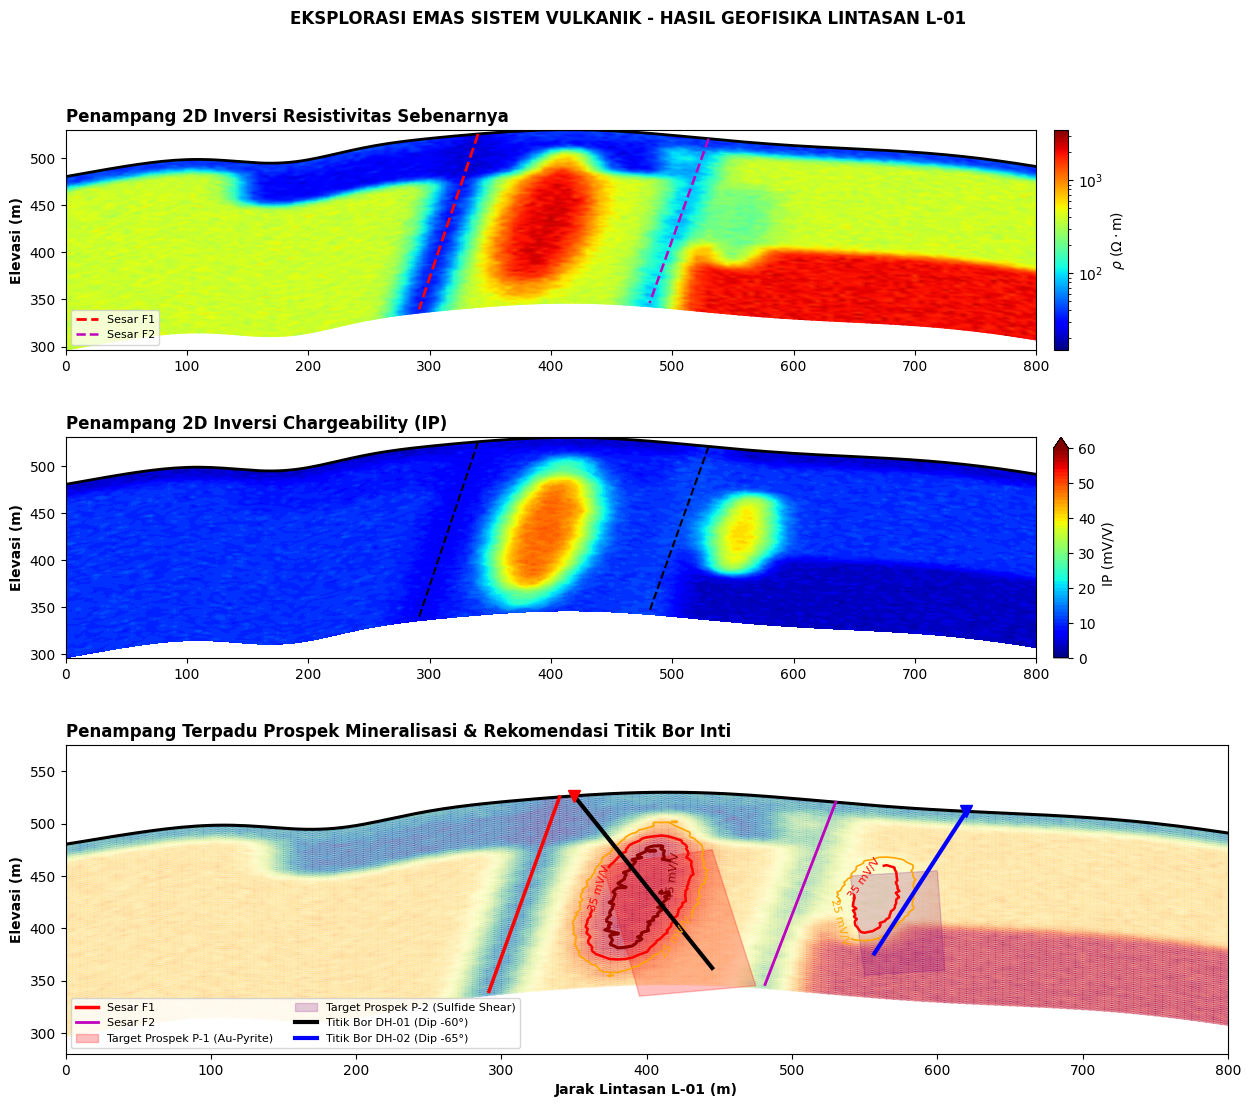

In [1]:
# %% [markdown]
# # EKSPLORASI EMAS MENGGUNAKAN RESISTIVITAS & IP
# Jalankan langsung di VS Code (Tekan tombol Run Cell atau Shift + Enter).
# Seluruh penampang akan langsung muncul di jendela interaktif VS Code (tanpa save image).

# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from scipy.ndimage import gaussian_filter

# 1. Parameter Geometri dan Topografi
dx, dz = 5.0, 2.0
x = np.arange(0, 805, dx)
z_rel = np.arange(0, 185, dz)

# Topografi perbukitan vulkanik
topo = 480.0 + 70.0 * np.exp(-((x - 420.0)/180.0)**2) + 20.0 * np.sin(x / 90.0) - 15.0 * np.exp(-((x - 180.0)/60.0)**2)

X, Z_rel = np.meshgrid(x, z_rel)
Z_elev = np.zeros_like(X)
for i in range(len(x)):
    Z_elev[:, i] = topo[i] - z_rel

# 2. Model Fisika-Geologi
log_res_true = np.full_like(X, 2.6)  # Batuan inang andesit propilitik (~400 Ohm.m)
chg_true = np.full_like(X, 10.0)     # Latar belakang IP (10 mV/V)

# Andesit segar dasar
log_res_true[(Z_rel > 110) & (X > 500)] = 3.3
chg_true[(Z_rel > 110) & (X > 500)] = 3.5

# Lapukan permukaan (0-12 m)
log_res_true[Z_rel <= 12] = 1.6
chg_true[Z_rel <= 12] = 4.0

# Tudung Lempung Argilik (10-45 m)
clay_mask = (Z_rel > 10) & (Z_rel < 45) & (X > 140) & (X < 500)
log_res_true[clay_mask] = 1.45
chg_true[clay_mask] = 8.5

# Sesar Utama F1 (NW-SE, dip 75° SW)
f1_center = 340.0 - 0.27 * Z_rel
f1_mask = np.abs(X - f1_center) < 18.0
log_res_true[f1_mask] = 1.35
chg_true[f1_mask] = 6.0

# Sesar Splay F2
f2_center = 530.0 - 0.27 * Z_rel
f2_mask = np.abs(X - f2_center) < 12.0
log_res_true[f2_mask] = 1.6
chg_true[f2_mask] = 12.0

# Prospek 1 (P-1): Inti Silisifikasi Urat Kuarsa & Pirit-Emas
p1_center = 410.0 - 0.25 * (Z_rel - 40)
dist_p1_x = (X - p1_center) / 32.0
dist_p1_z = (Z_rel - 100.0) / 60.0
p1_core = (dist_p1_x**2 + dist_p1_z**2) <= 1.0
p1_halo = (dist_p1_x**2 + dist_p1_z**2) <= 1.8

log_res_true[p1_halo] = 2.95
chg_true[p1_halo] = 28.0
log_res_true[p1_core] = 3.35  # >2000 Ohm.m
chg_true[p1_core] = 48.0      # 45-55 mV/V

# Prospek 2 (P-2): Rekahan Sulfida F2
p2_center = 570.0 - 0.25 * (Z_rel - 40)
p2_core = ((X - p2_center)/25.0)**2 + ((Z_rel - 90.0)/45.0)**2 <= 1.0
log_res_true[p2_core] = 2.3
chg_true[p2_core] = 42.0

# 3. Inversi 2D
np.random.seed(42)
log_res_inv = gaussian_filter(log_res_true, sigma=(1.8, 2.5)) + np.random.normal(0, 0.04, log_res_true.shape)
chg_inv = np.clip(gaussian_filter(chg_true, sigma=(1.8, 2.5)) + np.random.normal(0, 0.8, chg_true.shape), 1.0, 65.0)
res_inv = 10**log_res_inv

# Trase Sesar & Titik Bor
z_f = np.linspace(0, 180, 50)
x_f1, elev_f1 = 340.0 - 0.27 * z_f, np.interp(340.0 - 0.27 * z_f, x, topo) - z_f
x_f2, elev_f2 = 530.0 - 0.27 * z_f, np.interp(530.0 - 0.27 * z_f, x, topo) - z_f

# Pemboran DH-01 & DH-02
dh1_x0, dh1_z0 = 350.0, np.interp(350.0, x, topo)
dh1_x_end, dh1_z_end = dh1_x0 + 190.0 * np.cos(np.radians(60)), dh1_z0 - 190.0 * np.sin(np.radians(60))

dh2_x0, dh2_z0 = 620.0, np.interp(620.0, x, topo)
dh2_x_end, dh2_z_end = dh2_x0 - 150.0 * np.cos(np.radians(65)), dh2_z0 - 150.0 * np.sin(np.radians(65))

# %% [markdown]
# ### Visualisasi Penampang di VS Code

# %%
fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 1.4], hspace=0.35)

# 1. Penampang Resistivitas
ax1 = fig.add_subplot(gs[0])
cs1 = ax1.pcolormesh(X, Z_elev, res_inv, cmap='jet', norm=colors.LogNorm(vmin=15, vmax=3500), shading='gouraud')
ax1.plot(x, topo, 'k-', lw=2)
ax1.plot(x_f1, elev_f1, 'r--', lw=2, label='Sesar F1')
ax1.plot(x_f2, elev_f2, 'm--', lw=1.8, label='Sesar F2')
ax1.set_ylabel('Elevasi (m)', fontweight='bold')
ax1.set_title('Penampang 2D Inversi Resistivitas Sebenarnya', fontweight='bold', loc='left')
cbar1 = plt.colorbar(cs1, ax=ax1, pad=0.015, aspect=15)
cbar1.set_label(r'$\rho\ (\Omega\cdot\mathrm{m})$')
ax1.legend(loc='lower left', fontsize=8)

# 2. Penampang Chargeability (IP)
ax2 = fig.add_subplot(gs[1], sharex=ax1)
cs2 = ax2.contourf(X, Z_elev, chg_inv, levels=np.linspace(0, 60, 61), cmap='jet', extend='max')
ax2.plot(x, topo, 'k-', lw=2)
ax2.plot(x_f1, elev_f1, 'k--', lw=1.5)
ax2.plot(x_f2, elev_f2, 'k--', lw=1.5)
ax2.set_ylabel('Elevasi (m)', fontweight='bold')
ax2.set_title('Penampang 2D Inversi Chargeability (IP)', fontweight='bold', loc='left')
cbar2 = plt.colorbar(cs2, ax=ax2, pad=0.015, aspect=15, ticks=np.arange(0, 65, 10))
cbar2.set_label('IP (mV/V)')

# 3. Penampang Terpadu Prospek & Titik Bor
ax3 = fig.add_subplot(gs[2], sharex=ax1)
cs3 = ax3.pcolormesh(X, Z_elev, res_inv, cmap='Spectral_r', norm=colors.LogNorm(vmin=20, vmax=3000), alpha=0.4, shading='gouraud')
cs_ip = ax3.contour(X, Z_elev, chg_inv, levels=[25, 35, 45], colors=['orange', 'red', 'darkred'], linewidths=[1.2, 1.8, 2.2])
ax3.clabel(cs_ip, fmt='%d mV/V', fontsize=8)
ax3.plot(x, topo, 'k-', lw=2.2)
ax3.plot(x_f1, elev_f1, 'r-', lw=2.5, label='Sesar F1')
ax3.plot(x_f2, elev_f2, 'm-', lw=2.0, label='Sesar F2')

# Target Poligon
ax3.add_patch(patches.Polygon([[370, 460], [445, 475], [475, 345], [395, 335]], closed=True, 
                              edgecolor='red', facecolor='red', alpha=0.25, label='Target Prospek P-1 (Au-Pyrite)'))
ax3.add_patch(patches.Polygon([[540, 450], [600, 455], [605, 360], [550, 355]], closed=True, 
                              edgecolor='purple', facecolor='purple', alpha=0.2, label='Target Prospek P-2 (Sulfide Shear)'))

# Lintasan Bor DH-01 & DH-02
ax3.plot([dh1_x0, dh1_x_end], [dh1_z0, dh1_z_end], 'k-', lw=3, label='Titik Bor DH-01 (Dip -60°)')
ax3.plot(dh1_x0, dh1_z0, 'rv', markersize=9)
ax3.plot([dh2_x0, dh2_x_end], [dh2_z0, dh2_z_end], 'b-', lw=3, label='Titik Bor DH-02 (Dip -65°)')
ax3.plot(dh2_x0, dh2_z0, 'bv', markersize=9)

ax3.set_xlabel('Jarak Lintasan L-01 (m)', fontweight='bold')
ax3.set_ylabel('Elevasi (m)', fontweight='bold')
ax3.set_xlim(0, 800)
ax3.set_ylim(280, 575)
ax3.set_title('Penampang Terpadu Prospek Mineralisasi & Rekomendasi Titik Bor Inti', fontweight='bold', loc='left')
ax3.legend(loc='lower left', fontsize=8, ncol=2)

plt.suptitle('EKSPLORASI EMAS SISTEM VULKANIK - HASIL GEOFISIKA LINTASAN L-01', fontsize=12, fontweight='bold')
plt.show()  # Membuka langsung penampang di VS Code

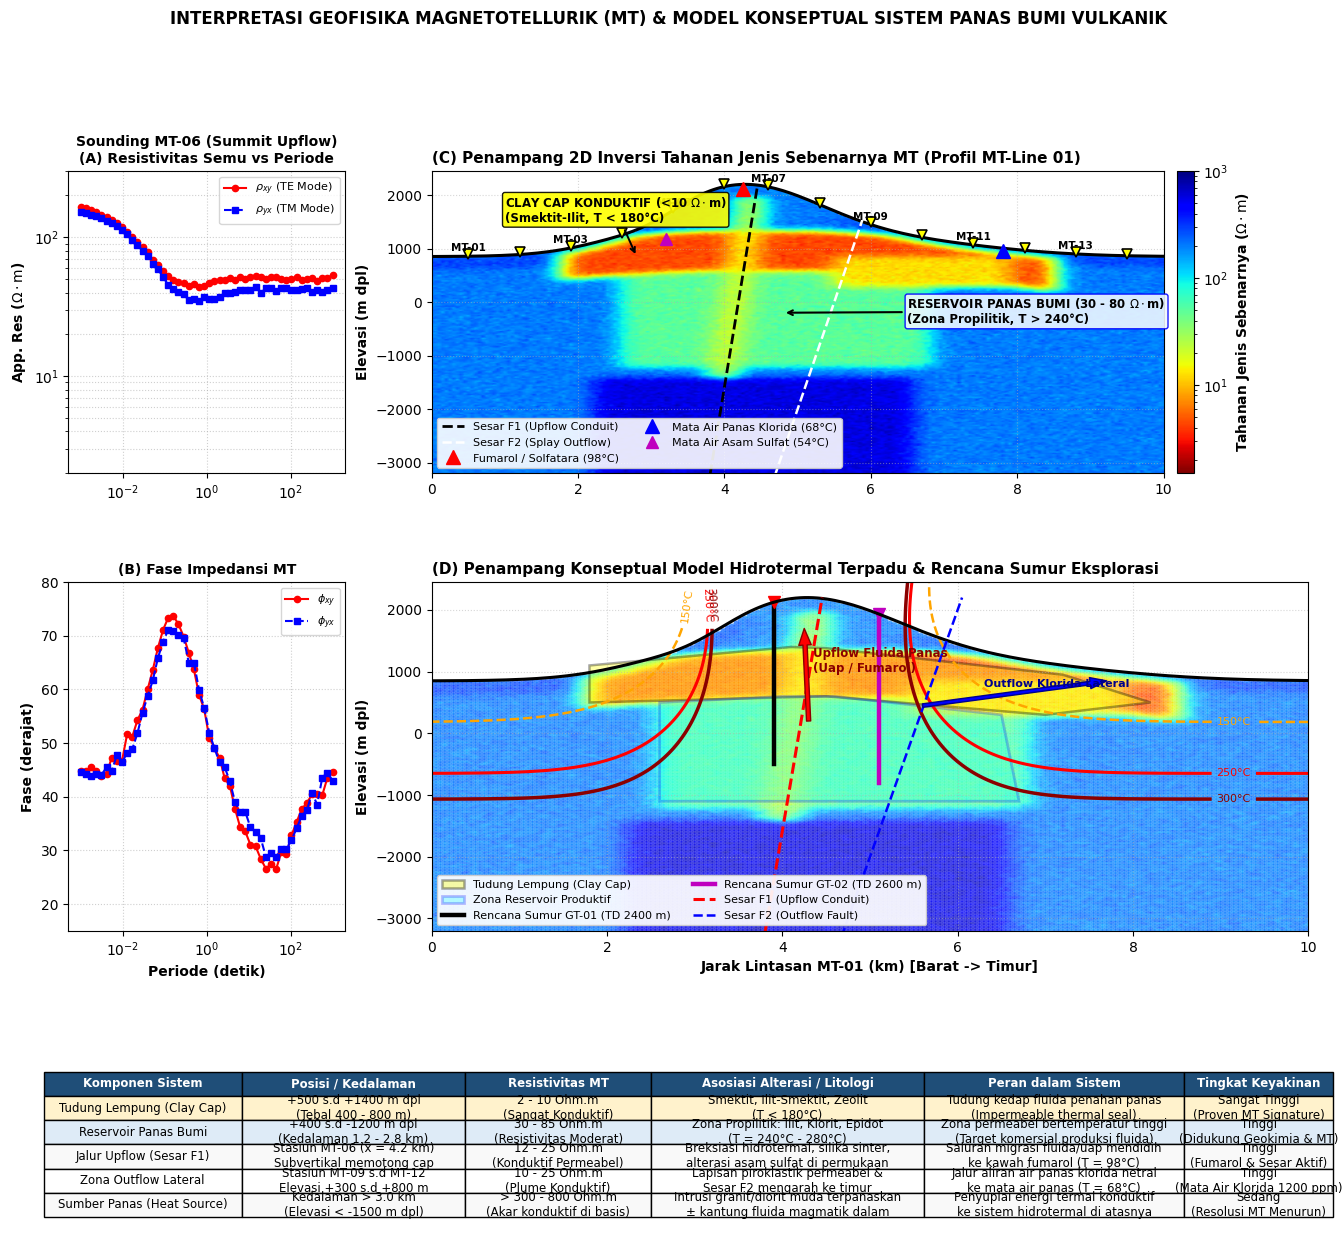

In [2]:
# %% [markdown]
# # EKSPLORASI PANAS BUMI MENGGUNAKAN MAGNETOTELLURIK (MT)
# Pemodelan Inversi 2D MT, Kurva Sounding, dan Model Konseptual Hidrotermal
# Petunjuk VS Code: Klik tombol "Run Cell" (atau Shift + Enter) pada sel '# %%' di bawah.

# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from scipy.ndimage import gaussian_filter

# 1. Parameter Geometri, Topografi & Stasiun MT
dx, dz = 50.0, 25.0
x = np.arange(0, 10050, dx)
elev_grid = np.arange(-3500, 2525, dz)

# Topografi Stratovolcano aktif (Puncak di x = 4.2 km, El. 2150 m dpl)
topo = 850.0 + 1300.0 * np.exp(-((x - 4200.0) / 1600.0)**2) + 250.0 * np.exp(-((x - 6500.0) / 1800.0)**2) - 120.0 * np.exp(-((x - 3000.0)/600.0)**2)
X, ELEV = np.meshgrid(x, elev_grid)

x_stations = np.array([500, 1200, 1900, 2600, 3300, 4000, 4600, 5300, 6000, 6700, 7400, 8100, 8800, 9500])
topo_stations = np.interp(x_stations, x, topo)
station_names = [f"MT-{i+1:02d}" for i in range(len(x_stations))]

# 2. Model Resistivitas Sebenarnya (True Geothermal Synthetic Model)
log_res_true = np.full_like(X, 2.3) # Background vulkanik regional ~200 Ohm.m

surf_dist = np.zeros_like(X)
for i in range(len(x)):
    surf_dist[:, i] = topo[i] - ELEV[:, i]

# Vulkanik segar dekat permukaan (Resistif 150-600 Ohm.m)
unaltered_mask = (surf_dist >= 0) & (surf_dist < 250) & (X < 3600) | ((surf_dist >= 0) & (surf_dist < 200) & (X > 5500))
log_res_true[unaltered_mask] = 2.45

# CLAY CAP (Smektit-Zeolit, T < 180°C): Sangat Konduktif (2 - 10 Ohm.m)
clay_top = 1350.0 - 0.00003 * (X - 4500.0)**2
clay_base = 600.0 - 0.000025 * (X - 4500.0)**2
clay_mask = (ELEV <= clay_top) & (ELEV >= clay_base) & (X >= 1800) & (X <= 8500) & (surf_dist > 80)
log_res_true[clay_mask] = 0.65 # ~4.5 Ohm.m

# RESERVOIR PANAS BUMI (Zona Propilitik: Ilit, Epidot, T > 240°C): Resistivitas Moderat (30 - 85 Ohm.m)
resv_mask = (ELEV < clay_base) & (ELEV >= -1200) & (X >= 2600) & (X <= 6800)
log_res_true[resv_mask] = 1.7 # ~50 Ohm.m

# UPFLOW ZONE & SESAR F1 (Saluran fluida mendidih ke Fumarol)
upflow_mask = (np.abs(X - (4200.0 + 0.12 * (ELEV - 500.0))) < 180.0) & (ELEV >= -1800) & (ELEV <= 1950)
log_res_true[upflow_mask] = 1.25 # ~18 Ohm.m

# OUTFLOW PLUME (Aliran lateral ke Mata Air Panas Klorida di Timur)
outflow_mask = (ELEV >= 300) & (ELEV <= 850) & (X >= 5500) & (X <= 7900)
log_res_true[outflow_mask] = 1.1 # ~12.5 Ohm.m

# BASEMENT RESISTIF / SUMBER PANAS INTRUSI (>300 Ohm.m)
heat_source_mask = (ELEV < -1400) & (np.abs(X - 4400.0) < 2200.0)
log_res_true[heat_source_mask] = 2.75

# 3. Simulasi Inversi 2D MT (Regularisasi Penghalusan)
np.random.seed(101)
log_res_inv = gaussian_filter(log_res_true, sigma=(2.2, 3.2)) + np.random.normal(0, 0.05, log_res_true.shape)
res_inv = 10**log_res_inv
res_inv[ELEV > np.interp(X, x, topo)] = np.nan

# 4. Kurva Sounding MT Stasiun MT-06 (Summit Upflow)
periods = np.logspace(-3, 3, 50)
app_res_xy = 180.0 / (1.0 + (periods / 0.02)**0.7) + 5.0 + 45.0 * (1.0 / (1.0 + (0.5 / periods)**1.1)) + np.random.normal(0, 1.2, len(periods))
app_res_yx = 160.0 / (1.0 + (periods / 0.025)**0.75) + 4.2 + 38.0 * (1.0 / (1.0 + (0.7 / periods)**1.05)) + np.random.normal(0, 1.0, len(periods))
app_phase_xy = 45.0 + 28.0 * np.exp(-((np.log10(periods) + 0.8)/0.8)**2) - 18.0 * np.exp(-((np.log10(periods) - 1.5)/0.9)**2) + np.random.normal(0, 1.0, len(periods))
app_phase_yx = 45.0 + 26.0 * np.exp(-((np.log10(periods) + 0.75)/0.8)**2) - 16.0 * np.exp(-((np.log10(periods) - 1.6)/0.9)**2) + np.random.normal(0, 0.9, len(periods))

elev_f = np.linspace(-3500, 2200, 100)
x_f1, x_f2 = 4250.0 + 0.12 * (elev_f - 500.0), 5600.0 + 0.25 * (elev_f - 400.0)

# %% [markdown]
# ### Visualisasi Komprehensif di VS Code

# %%
fig = plt.figure(figsize=(16, 14), dpi=100)
gs = fig.add_gridspec(3, 2, width_ratios=[1.2, 3.8], height_ratios=[1.3, 1.5, 0.9], hspace=0.38, wspace=0.15)

# Subplot A: Kurva Resistivitas Semu Sounding MT-06
ax_sound_res = fig.add_subplot(gs[0, 0])
ax_sound_res.loglog(periods, app_res_xy, 'ro-', markersize=4.5, label=r'$\rho_{xy}$ (TE Mode)')
ax_sound_res.loglog(periods, app_res_yx, 'bs--', markersize=4.5, label=r'$\rho_{yx}$ (TM Mode)')
ax_sound_res.set_ylabel(r'App. Res ($\Omega\cdot\mathrm{m}$)', fontsize=10, fontweight='bold')
ax_sound_res.set_title('Sounding MT-06 (Summit Upflow)\n(A) Resistivitas Semu vs Periode', fontsize=10, fontweight='bold')
ax_sound_res.grid(True, which='both', linestyle=':', alpha=0.6)
ax_sound_res.legend(fontsize=8, loc='upper right')
ax_sound_res.set_ylim(2, 300)

# Subplot B: Fase Impedansi Sounding MT-06
ax_sound_pha = fig.add_subplot(gs[1, 0], sharex=ax_sound_res)
ax_sound_pha.semilogx(periods, app_phase_xy, 'ro-', markersize=4.5, label=r'$\phi_{xy}$')
ax_sound_pha.semilogx(periods, app_phase_yx, 'bs--', markersize=4.5, label=r'$\phi_{yx}$')
ax_sound_pha.set_xlabel('Periode (detik)', fontsize=10, fontweight='bold')
ax_sound_pha.set_ylabel('Fase (derajat)', fontsize=10, fontweight='bold')
ax_sound_pha.set_title('(B) Fase Impedansi MT', fontsize=10, fontweight='bold')
ax_sound_pha.set_ylim(15, 80)
ax_sound_pha.grid(True, which='both', linestyle=':', alpha=0.6)
ax_sound_pha.legend(fontsize=8, loc='upper right')

# Subplot C: Penampang 2D Inversi MT Resistivitas Sebenarnya
ax_inv = fig.add_subplot(gs[0, 1])
norm_mt = colors.LogNorm(vmin=1.5, vmax=1000)
cs_mt = ax_inv.pcolormesh(X/1000.0, ELEV, res_inv, cmap='jet_r', norm=norm_mt, shading='gouraud')
ax_inv.plot(x/1000.0, topo, 'k-', lw=2.2)
ax_inv.plot(x_stations/1000.0, topo_stations + 40, 'kv', markersize=6.5, markeredgewidth=1.2, markerfacecolor='yellow')
for st_x, st_el, st_nm in zip(x_stations[::2], topo_stations[::2], station_names[::2]):
    ax_inv.text(st_x/1000.0, st_el + 90, st_nm, fontsize=7.5, ha='center', fontweight='bold')

ax_inv.plot(x_f1/1000.0, elev_f, 'k--', lw=2.0, label='Sesar F1 (Upflow Conduit)')
ax_inv.plot(x_f2/1000.0, elev_f, 'w--', lw=1.8, label='Sesar F2 (Splay Outflow)')
ax_inv.plot([4.25], [2120], 'r^', markersize=10, label='Fumarol / Solfatara (98°C)')
ax_inv.plot([7.8], [960], 'b^', markersize=10, label='Mata Air Panas Klorida (68°C)')
ax_inv.plot([3.2], [1180], 'm^', markersize=9, label='Mata Air Asam Sulfat (54°C)')

ax_inv.annotate(r'CLAY CAP KONDUKTIF (<10 $\Omega\cdot$m)' + '\n' + r'(Smektit-Ilit, T < 180°C)', 
                xy=(2.8, 850), xytext=(1.0, 1500),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.4),
                fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='yellow', alpha=0.9))

ax_inv.annotate(r'RESERVOIR PANAS BUMI (30 - 80 $\Omega\cdot$m)' + '\n' + r'(Zona Propilitik, T > 240°C)', 
                xy=(4.8, -200), xytext=(6.5, -400),
                arrowprops=dict(facecolor='blue', arrowstyle='->', lw=1.5),
                fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='aliceblue', ec='blue', alpha=0.9))

ax_inv.set_ylabel('Elevasi (m dpl)', fontsize=10, fontweight='bold')
ax_inv.set_xlim(0, 10.0)
ax_inv.set_ylim(-3200, 2450)
ax_inv.set_title('(C) Penampang 2D Inversi Tahanan Jenis Sebenarnya MT (Profil MT-Line 01)', fontsize=11, fontweight='bold', loc='left')
ax_inv.grid(True, linestyle=':', alpha=0.5)
ax_inv.legend(loc='lower left', fontsize=8, framealpha=0.9, ncol=2)
cbar_mt = plt.colorbar(cs_mt, ax=ax_inv, pad=0.015, aspect=18)
cbar_mt.set_label(r'Tahanan Jenis Sebenarnya ($\Omega\cdot\mathrm{m}$)', fontsize=10, fontweight='bold')

# Subplot D: Penampang Konseptual Hidrotermal & Titik Sumur Eksplorasi
ax_con = fig.add_subplot(gs[1, 1], sharex=ax_inv)
cs_con_bg = ax_con.pcolormesh(X/1000.0, ELEV, res_inv, cmap='jet_r', norm=norm_mt, alpha=0.35, shading='gouraud')

# Poligon Clay Cap & Reservoir
ax_con.add_patch(patches.Polygon([[1.8, 1100], [4.1, 1400], [4.5, 1380], [7.2, 950], [8.2, 500], [7.0, 300], [4.5, 600], [1.8, 500]], 
                                 closed=True, edgecolor='black', facecolor='yellow', alpha=0.35, lw=1.8, label='Tudung Lempung (Clay Cap)'))
ax_con.add_patch(patches.Polygon([[2.6, 500], [4.0, 600], [4.6, 600], [6.5, 300], [6.7, -1100], [2.6, -1100]], 
                                 closed=True, edgecolor='blue', facecolor='cyan', alpha=0.25, lw=2.0, label='Zona Reservoir Produktif'))

# Kontur Isotermal (°C)
iso_150 = ax_con.contour(X/1000.0, ELEV, 70.0 + 0.12 * (topo[0] - ELEV) + 160.0 * np.exp(-((X/1000.0 - 4.3)/1.8)**2 + (ELEV/2200.0)), levels=[150], colors=['orange'], linewidths=[1.8], linestyles=['--'])
iso_250 = ax_con.contour(X/1000.0, ELEV, 70.0 + 0.12 * (topo[0] - ELEV) + 240.0 * np.exp(-((X/1000.0 - 4.3)/1.6)**2 + (ELEV/2500.0)), levels=[250], colors=['red'], linewidths=[2.2])
iso_300 = ax_con.contour(X/1000.0, ELEV, 70.0 + 0.12 * (topo[0] - ELEV) + 310.0 * np.exp(-((X/1000.0 - 4.3)/1.5)**2 + (ELEV/2800.0)), levels=[300], colors=['darkred'], linewidths=[2.5])
ax_con.clabel(iso_150, fmt='%d°C', fontsize=8)
ax_con.clabel(iso_250, fmt='%d°C', fontsize=8)
ax_con.clabel(iso_300, fmt='%d°C', fontsize=8)

# Vektor Aliran Fluida
ax_con.annotate('', xy=(4.25, 1700), xytext=(4.3, 200), arrowprops=dict(facecolor='red', edgecolor='darkred', width=3, headwidth=9))
ax_con.text(4.35, 1000, 'Upflow Fluida Panas\n(Uap / Fumarol)', color='darkred', fontsize=8.5, fontweight='bold')
ax_con.annotate('', xy=(7.7, 850), xytext=(5.6, 450), arrowprops=dict(facecolor='blue', edgecolor='darkblue', width=2.5, headwidth=8))
ax_con.text(6.3, 750, 'Outflow Klorida Lateral', color='darkblue', fontsize=8, fontweight='bold')

# Rencana Sumur GT-01 & GT-02
well1_top = np.interp(3900.0, x, topo)
ax_con.plot([3.9, 3.9], [well1_top, -500.0], 'k-', lw=3.2, label='Rencana Sumur GT-01 (TD 2400 m)')
ax_con.plot(3.9, well1_top, 'rv', markersize=9)

well2_top = np.interp(5100.0, x, topo)
ax_con.plot([5.1, 5.1], [well2_top, -800.0], 'm-', lw=3.2, label='Rencana Sumur GT-02 (TD 2600 m)')
ax_con.plot(5.1, well2_top, 'mv', markersize=9)

ax_con.plot(x/1000.0, topo, 'k-', lw=2.2)
ax_con.plot(x_f1/1000.0, elev_f, 'r--', lw=2.2, label='Sesar F1 (Upflow Conduit)')
ax_con.plot(x_f2/1000.0, elev_f, 'b--', lw=1.8, label='Sesar F2 (Outflow Fault)')
ax_con.set_xlabel('Jarak Lintasan MT-01 (km) [Barat -> Timur]', fontsize=10, fontweight='bold')
ax_con.set_ylabel('Elevasi (m dpl)', fontsize=10, fontweight='bold')
ax_con.set_ylim(-3200, 2450)
ax_con.set_title('(D) Penampang Konseptual Model Hidrotermal Terpadu & Rencana Sumur Eksplorasi', fontsize=11, fontweight='bold', loc='left')
ax_con.grid(True, linestyle=':', alpha=0.5)
ax_con.legend(loc='lower left', fontsize=8, framealpha=0.92, ncol=2)

# Subplot E: Tabel Ringkasan Komponen Sistem Panas Bumi
ax_tbl = fig.add_subplot(gs[2, :])
ax_tbl.axis('off')
table_data = [
    ["Komponen Sistem", "Posisi / Kedalaman", "Resistivitas MT", "Asosiasi Alterasi / Litologi", "Peran dalam Sistem", "Tingkat Keyakinan"],
    ["Tudung Lempung (Clay Cap)", "+500 s.d +1400 m dpl\n(Tebal 400 - 800 m)", "2 - 10 Ohm.m\n(Sangat Konduktif)", "Smektit, Ilit-Smektit, Zeolit\n(T < 180°C)", "Tudung kedap fluida penahan panas\n(Impermeable thermal seal)", "Sangat Tinggi\n(Proven MT Signature)"],
    ["Reservoir Panas Bumi", "+400 s.d -1200 m dpl\n(Kedalaman 1.2 - 2.8 km)", "30 - 85 Ohm.m\n(Resistivitas Moderat)", "Zona Propilitik: Ilit, Klorit, Epidot\n(T = 240°C - 280°C)", "Zona permeabel bertemperatur tinggi\n(Target komersial produksi fluida)", "Tinggi\n(Didukung Geokimia & MT)"],
    ["Jalur Upflow (Sesar F1)", "Stasiun MT-06 (x = 4.2 km)\nSubvertikal memotong cap", "12 - 25 Ohm.m\n(Konduktif Permeabel)", "Breksiasi hidrotermal, silika sinter,\nalterasi asam sulfat di permukaan", "Saluran migrasi fluida/uap mendidih\nke kawah fumarol (T = 98°C)", "Tinggi\n(Fumarol & Sesar Aktif)"],
    ["Zona Outflow Lateral", "Stasiun MT-09 s.d MT-12\nElevasi +300 s.d +800 m", "10 - 25 Ohm.m\n(Plume Konduktif)", "Lapisan piroklastik permeabel &\nSesar F2 mengarah ke timur", "Jalur aliran air panas klorida netral\nke mata air panas (T = 68°C)", "Tinggi\n(Mata Air Klorida 1200 ppm)"],
    ["Sumber Panas (Heat Source)", "Kedalaman > 3.0 km\n(Elevasi < -1500 m dpl)", "> 300 - 800 Ohm.m\n(Akar konduktif di basis)", "Intrusi granit/diorit muda terpanaskan\n± kantung fluida magmatik dalam", "Penyuplai energi termal konduktif\nke sistem hidrotermal di atasnya", "Sedang\n(Resolusi MT Menurun)"]
]

tbl = ax_tbl.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.16, 0.18, 0.15, 0.22, 0.21, 0.12])
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1.0, 1.45)
for j in range(6):
    tbl[0, j].set_facecolor('#1f4e78')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
for i in range(1, len(table_data)):
    bg_col = '#fff2cc' if i == 1 else ('#deebf7' if i == 2 else ('#f9f9f9' if i % 2 == 1 else '#ffffff'))
    for j in range(6):
        tbl[i, j].set_facecolor(bg_col)

plt.suptitle('INTERPRETASI GEOFISIKA MAGNETOTELLURIK (MT) & MODEL KONSEPTUAL SISTEM PANAS BUMI VULKANIK', fontsize=12, fontweight='bold', y=0.995)
plt.show() # Tampilkan langsung di jendela interaktif VS Code

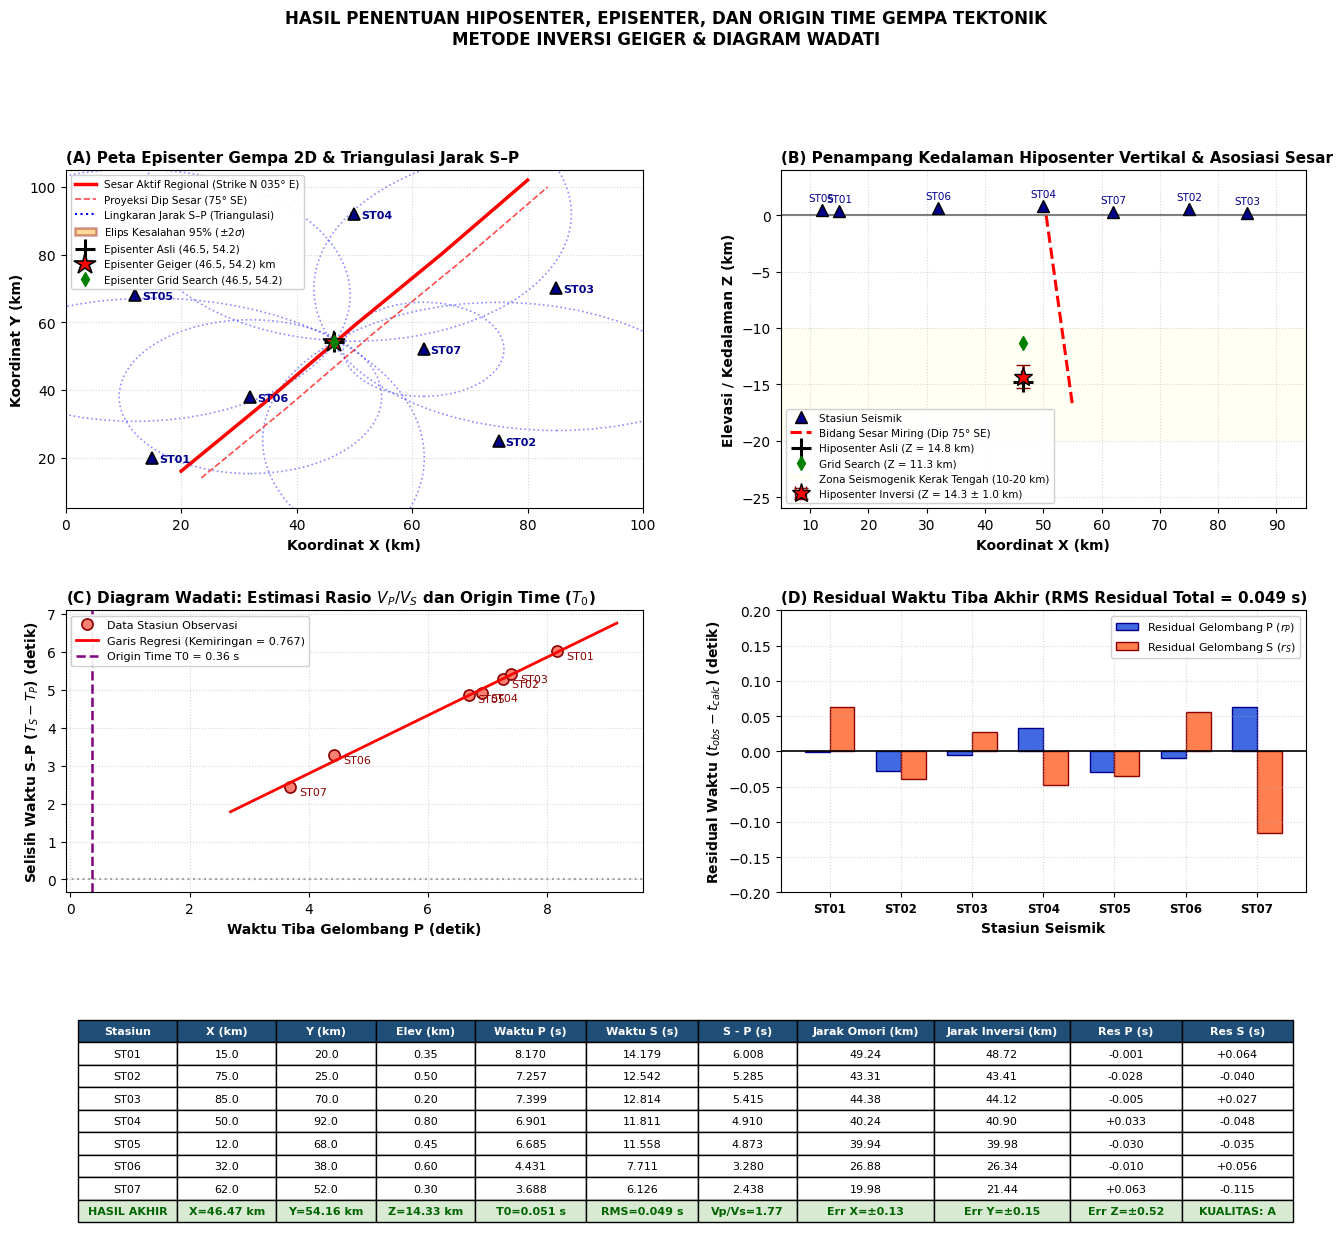

In [3]:
# %% [markdown]
# # PENENTUAN HIPOSENTER & EPISENTER GEMPA MENGGUNAKAN GELOMBANG P DAN S
# Implementasi: Diagram Wadati, Triangulasi S-P, Inversi Geiger (Gauss-Newton), Grid Search 3D.
# Petunjuk VS Code: Klik tombol "Run Cell" (atau Shift + Enter) pada sel '# %%' di bawah.

# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

# 1. Parameter Model Kecepatan Kerak 1D & Jaringan Stasiun Seismik
Vp = 6.00   # km/s
Vs = 3.464  # km/s -> Vp/Vs = 1.732 (Poisson Solid)
vp_vs_ratio = Vp / Vs
omori_k = (Vp * Vs) / (Vp - Vs) # Konstanta Omori = 8.196 km/s

stations = {
    'ST01': {'x': 15.0, 'y': 20.0, 'z': 0.35},
    'ST02': {'x': 75.0, 'y': 25.0, 'z': 0.50},
    'ST03': {'x': 85.0, 'y': 70.0, 'z': 0.20},
    'ST04': {'x': 50.0, 'y': 92.0, 'z': 0.80},
    'ST05': {'x': 12.0, 'y': 68.0, 'z': 0.45},
    'ST06': {'x': 32.0, 'y': 38.0, 'z': 0.60},
    'ST07': {'x': 62.0, 'y': 52.0, 'z': 0.30}
}

# Parameter Sintetis Sebenarnya (True Source)
true_x, true_y, true_z, true_t0 = 46.5, 54.2, -14.8, 0.00

# 2. Simulasi Waktu Tiba Observasi (P & S Picks dengan Noise)
np.random.seed(42)
st_names = list(stations.keys())
st_x = np.array([stations[s]['x'] for s in st_names])
st_y = np.array([stations[s]['y'] for s in st_names])
st_z = np.array([stations[s]['z'] for s in st_names])

true_dist = np.sqrt((st_x - true_x)**2 + (st_y - true_y)**2 + (st_z - true_z)**2)
t_p_obs = true_t0 + (true_dist / Vp) + np.random.normal(0, 0.04, len(st_names))
t_s_obs = true_t0 + (true_dist / Vs) + np.random.normal(0, 0.08, len(st_names))
t_sp = t_s_obs - t_p_obs
dist_sp_est = t_sp * omori_k

# 3. Diagram Wadati (Estimasi Vp/Vs dan Origin Time Awal)
slope_w, intercept_w = np.polyfit(t_p_obs, t_sp, 1)
vp_vs_wadati = slope_w + 1.0
t0_wadati = -intercept_w / slope_w

# 4. Inversi Non-Linier Kuadrat Terkecil (Metode Geiger)
m = np.array([np.mean(st_x), np.mean(st_y), -10.0, t0_wadati]) # Tebakan awal
for it in range(15):
    R = np.sqrt((st_x - m[0])**2 + (st_y - m[1])**2 + (st_z - m[2])**2)
    t_p_calc = m[3] + R / Vp
    t_s_calc = m[3] + R / Vs
    res = np.concatenate([t_p_obs - t_p_calc, t_s_obs - t_s_calc])
    
    # Matriks Jacobi G (2N baris x 4 kolom)
    G_p = np.column_stack([-(st_x - m[0])/(Vp*R), -(st_y - m[1])/(Vp*R), -(st_z - m[2])/(Vp*R), np.ones(len(st_names))])
    G_s = np.column_stack([-(st_x - m[0])/(Vs*R), -(st_y - m[1])/(Vs*R), -(st_z - m[2])/(Vs*R), np.ones(len(st_names))])
    G = np.vstack([G_p, G_s])
    
    # Matriks Pembobotan W
    W = np.diag(np.concatenate([np.full(len(st_names), 1.0/0.05**2), np.full(len(st_names), 1.0/0.10**2)]))
    dm = np.linalg.inv(G.T @ W @ G + 0.05 * np.eye(4)) @ (G.T @ W @ res)
    m += dm
    if np.linalg.norm(dm) < 1e-4:
        break

cov_m = np.linalg.inv(G.T @ W @ G)
sigma_m = np.sqrt(np.diag(cov_m))
est_x, est_y, est_z, est_t0 = m[0], m[1], m[2], m[3]
err_x, err_y, err_z, err_t0 = sigma_m[0], sigma_m[1], sigma_m[2], sigma_m[3]

final_r = np.sqrt((st_x - est_x)**2 + (st_y - est_y)**2 + (st_z - est_z)**2)
final_res_p = t_p_obs - (est_t0 + final_r / Vp)
final_res_s = t_s_obs - (est_t0 + final_r / Vs)
final_rms = np.sqrt(np.mean(np.concatenate([final_res_p, final_res_s])**2))

# 5. Verifikasi Grid Search 3D
gx = np.linspace(est_x - 10, est_x + 10, 21)
gy = np.linspace(est_y - 10, est_y + 10, 21)
gz = np.linspace(est_z - 8, est_z + 8, 17)
best_misfit, grid_best = 1e9, [0, 0, 0]
for xi in gx:
    for yi in gy:
        for zi in gz:
            ri = np.sqrt((st_x - xi)**2 + (st_y - yi)**2 + (st_z - zi)**2)
            mf = np.sum((t_p_obs - (t0_wadati + ri/Vp))**2) + np.sum((t_s_obs - (t0_wadati + ri/Vs))**2)
            if mf < best_misfit:
                best_misfit, grid_best = mf, [xi, yi, zi]

# 6. Sesar Aktif Regional (Strike N 035° E, Dip 75° SE)
fault_x = np.array([20.0, 35.0, 50.0, 65.0, 80.0])
fault_y = np.array([16.0, 37.0, 59.0, 80.0, 102.0])

# %% [markdown]
# ### Visualisasi Komprehensif di VS Code

# %%
fig = plt.figure(figsize=(16, 14), dpi=100)
gs = fig.add_gridspec(3, 2, width_ratios=[1.1, 1.0], height_ratios=[1.2, 1.0, 0.9], hspace=0.35, wspace=0.25)

# (A) Peta Episenter 2D & Triangulasi Jarak S-P
ax_map = fig.add_subplot(gs[0, 0])
ax_map.plot(fault_x, fault_y, 'r-', lw=2.5, label='Sesar Aktif Regional (Strike N 035° E)')
ax_map.plot(fault_x + 3.5, fault_y - 2.0, 'r--', lw=1.2, alpha=0.7, label='Proyeksi Dip Sesar (75° SE)')

for s_name, sx, sy, s_dist in zip(st_names, st_x, st_y, dist_sp_est):
    r_surf = np.sqrt(max(0, s_dist**2 - abs(est_z)**2))
    circle = plt.Circle((sx, sy), r_surf, color='blue', fill=False, linestyle=':', alpha=0.45, lw=1.2)
    ax_map.add_patch(circle)
    ax_map.plot(sx, sy, '^', markersize=9, color='darkblue', markeredgecolor='black', markeredgewidth=1.2)
    ax_map.text(sx + 1.2, sy - 1.2, s_name, fontsize=8, fontweight='bold', color='darkblue')

ax_map.plot([], [], 'b:', label='Lingkaran Jarak S–P (Triangulasi)')
ax_map.add_patch(patches.Ellipse((est_x, est_y), width=2*err_x*1.96, height=2*err_y*1.96, angle=35,
                                 facecolor='orange', edgecolor='darkred', alpha=0.4, lw=1.8, label=r'Elips Kesalahan 95% ($\pm 2\sigma$)'))
ax_map.plot(true_x, true_y, 'k+', markersize=14, markeredgewidth=2.2, label=f'Episenter Asli ({true_x:.1f}, {true_y:.1f})')
ax_map.plot(est_x, est_y, 'r*', markersize=16, markeredgecolor='black', markeredgewidth=1.2, label=f'Episenter Geiger ({est_x:.1f}, {est_y:.1f}) km')
ax_map.plot(grid_best[0], grid_best[1], 'gd', markersize=7, label=f'Episenter Grid Search ({grid_best[0]:.1f}, {grid_best[1]:.1f})')
ax_map.set_xlabel('Koordinat X (km)', fontsize=10, fontweight='bold')
ax_map.set_ylabel('Koordinat Y (km)', fontsize=10, fontweight='bold')
ax_map.set_xlim(0, 100); ax_map.set_ylim(5, 105)
ax_map.set_title('(A) Peta Episenter Gempa 2D & Triangulasi Jarak S–P', fontsize=11, fontweight='bold', loc='left')
ax_map.grid(True, linestyle=':', alpha=0.5); ax_map.legend(loc='upper left', fontsize=7.5, framealpha=0.92)

# (B) Penampang Kedalaman Vertikal Hiposenter
ax_depth = fig.add_subplot(gs[0, 1])
ax_depth.axhline(0, color='gray', linestyle='-', lw=1.5)
ax_depth.plot(st_x, st_z, '^', markersize=8, color='darkblue', markeredgecolor='k', label='Stasiun Seismik')
for s_name, sx, sz in zip(st_names, st_x, st_z):
    ax_depth.text(sx, sz + 0.8, s_name, fontsize=7.5, ha='center', color='darkblue')

fault_dip_x = np.linspace(35, 55, 50)
fault_dip_z = -np.tan(np.radians(75)) * (fault_dip_x - 50.5)
valid_f = (fault_dip_z <= 0) & (fault_dip_z >= -28)
ax_depth.plot(fault_dip_x[valid_f], fault_dip_z[valid_f], 'r--', lw=2.2, label='Bidang Sesar Miring (Dip 75° SE)')

ax_depth.errorbar(est_x, est_z, yerr=err_z*1.96, xerr=err_x*1.96, fmt='r*', markersize=14, 
                  markeredgecolor='k', capsize=5, elinewidth=1.8, ecolor='darkred',
                  label=f'Hiposenter Inversi (Z = {abs(est_z):.1f} ± {err_z*1.96:.1f} km)')
ax_depth.plot(true_x, true_z, 'k+', markersize=14, markeredgewidth=2.2, label=f'Hiposenter Asli (Z = {abs(true_z):.1f} km)')
ax_depth.plot(grid_best[0], grid_best[2], 'gd', markersize=7, label=f'Grid Search (Z = {abs(grid_best[2]):.1f} km)')
ax_depth.axhspan(-10, -20, facecolor='lightyellow', alpha=0.35, label='Zona Seismogenik Kerak Tengah (10-20 km)')
ax_depth.set_xlabel('Koordinat X (km)', fontsize=10, fontweight='bold')
ax_depth.set_ylabel('Elevasi / Kedalaman Z (km)', fontsize=10, fontweight='bold')
ax_depth.set_xlim(5, 95); ax_depth.set_ylim(-26, 4)
ax_depth.set_title('(B) Penampang Kedalaman Hiposenter Vertikal & Asosiasi Sesar', fontsize=11, fontweight='bold', loc='left')
ax_depth.grid(True, linestyle=':', alpha=0.5); ax_depth.legend(loc='lower left', fontsize=7.5, framealpha=0.92)

# (C) Diagram Wadati
ax_wadati = fig.add_subplot(gs[1, 0])
tp_line = np.linspace(min(t_p_obs) - 1.0, max(t_p_obs) + 1.0, 100)
ax_wadati.plot(t_p_obs, t_sp, 'o', markersize=8, markerfacecolor='salmon', markeredgecolor='darkred', markeredgewidth=1.2, label='Data Stasiun Observasi')
ax_wadati.plot(tp_line, slope_w * tp_line + intercept_w, 'r-', lw=2.0, label=f'Garis Regresi (Kemiringan = {slope_w:.3f})')
ax_wadati.axhline(0, color='gray', linestyle=':', alpha=0.7)
ax_wadati.axvline(t0_wadati, color='purple', linestyle='--', lw=1.8, label=f'Origin Time T0 = {t0_wadati:.2f} s')
for s_name, tp_val, tsp_val in zip(st_names, t_p_obs, t_sp):
    ax_wadati.text(tp_val + 0.15, tsp_val - 0.2, s_name, fontsize=8, color='darkred')
ax_wadati.set_xlabel('Waktu Tiba Gelombang P (detik)', fontsize=10, fontweight='bold')
ax_wadati.set_ylabel('Selisih Waktu S–P ($T_S - T_P$) (detik)', fontsize=10, fontweight='bold')
ax_wadati.set_title(r'(C) Diagram Wadati: Estimasi Rasio $V_P/V_S$ dan Origin Time ($T_0$)', fontsize=11, fontweight='bold', loc='left')
ax_wadati.grid(True, linestyle=':', alpha=0.5); ax_wadati.legend(loc='upper left', fontsize=8, framealpha=0.92)

# (D) Residual Waktu Tiba
ax_res = fig.add_subplot(gs[1, 1])
x_ind = np.arange(len(st_names))
w_bar = 0.35
ax_res.bar(x_ind - w_bar/2, final_res_p, width=w_bar, color='royalblue', edgecolor='darkblue', label='Residual Gelombang P ($r_P$)')
ax_res.bar(x_ind + w_bar/2, final_res_s, width=w_bar, color='coral', edgecolor='darkred', label='Residual Gelombang S ($r_S$)')
ax_res.axhline(0, color='black', lw=1.2)
ax_res.set_xticks(x_ind); ax_res.set_xticklabels(st_names, fontweight='bold', fontsize=8.5)
ax_res.set_xlabel('Stasiun Seismik', fontsize=10, fontweight='bold')
ax_res.set_ylabel('Residual Waktu ($t_{obs} - t_{calc}$) (detik)', fontsize=10, fontweight='bold')
ax_res.set_ylim(-0.20, 0.20)
ax_res.set_title(f'(D) Residual Waktu Tiba Akhir (RMS Residual Total = {final_rms:.3f} s)', fontsize=11, fontweight='bold', loc='left')
ax_res.grid(True, linestyle=':', alpha=0.5); ax_res.legend(loc='upper right', fontsize=8, framealpha=0.92)

# (E) Tabel Rekapitulasi Perhitungan
ax_tbl = fig.add_subplot(gs[2, :])
ax_tbl.axis('off')
table_rows = [
    ["Stasiun", "X (km)", "Y (km)", "Elev (km)", "Waktu P (s)", "Waktu S (s)", "S - P (s)", "Jarak Omori (km)", "Jarak Inversi (km)", "Res P (s)", "Res S (s)"]
]
for s_n, sx, sy, sz, tp, ts, tsp, dom, r_inv, rp, rs in zip(st_names, st_x, st_y, st_z, t_p_obs, t_s_obs, t_sp, dist_sp_est, 
                                                              final_r, final_res_p, final_res_s):
    table_rows.append([s_n, f"{sx:.1f}", f"{sy:.1f}", f"{sz:.2f}", f"{tp:.3f}", f"{ts:.3f}", f"{tsp:.3f}",
                       f"{dom:.2f}", f"{r_inv:.2f}", f"{rp:+.3f}", f"{rs:+.3f}"])

table_rows.append([
    "HASIL AKHIR", f"X={est_x:.2f} km", f"Y={est_y:.2f} km", f"Z={abs(est_z):.2f} km",
    f"T0={est_t0:.3f} s", f"RMS={final_rms:.3f} s", f"Vp/Vs={vp_vs_wadati:.2f}",
    f"Err X=±{err_x:.2f}", f"Err Y=±{err_y:.2f}", f"Err Z=±{err_z:.2f}", "KUALITAS: A"
])

tbl = ax_tbl.table(cellText=table_rows, loc='center', cellLoc='center', 
                   colWidths=[0.08, 0.08, 0.08, 0.08, 0.09, 0.09, 0.08, 0.11, 0.11, 0.09, 0.09])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.0); tbl.scale(1.0, 1.35)
for j in range(11):
    tbl[0, j].set_facecolor('#1f4e78'); tbl[0, j].set_text_props(color='white', fontweight='bold')
    tbl[len(st_names) + 1, j].set_facecolor('#d9ead3')
    tbl[len(st_names) + 1, j].set_text_props(fontweight='bold', color='darkgreen')

plt.suptitle('HASIL PENENTUAN HIPOSENTER, EPISENTER, DAN ORIGIN TIME GEMPA TEKTONIK\nMETODE INVERSI GEIGER & DIAGRAM WADATI', fontsize=12, fontweight='bold', y=0.995)
plt.show() # Tampilkan langsung di jendela interaktif VS Code

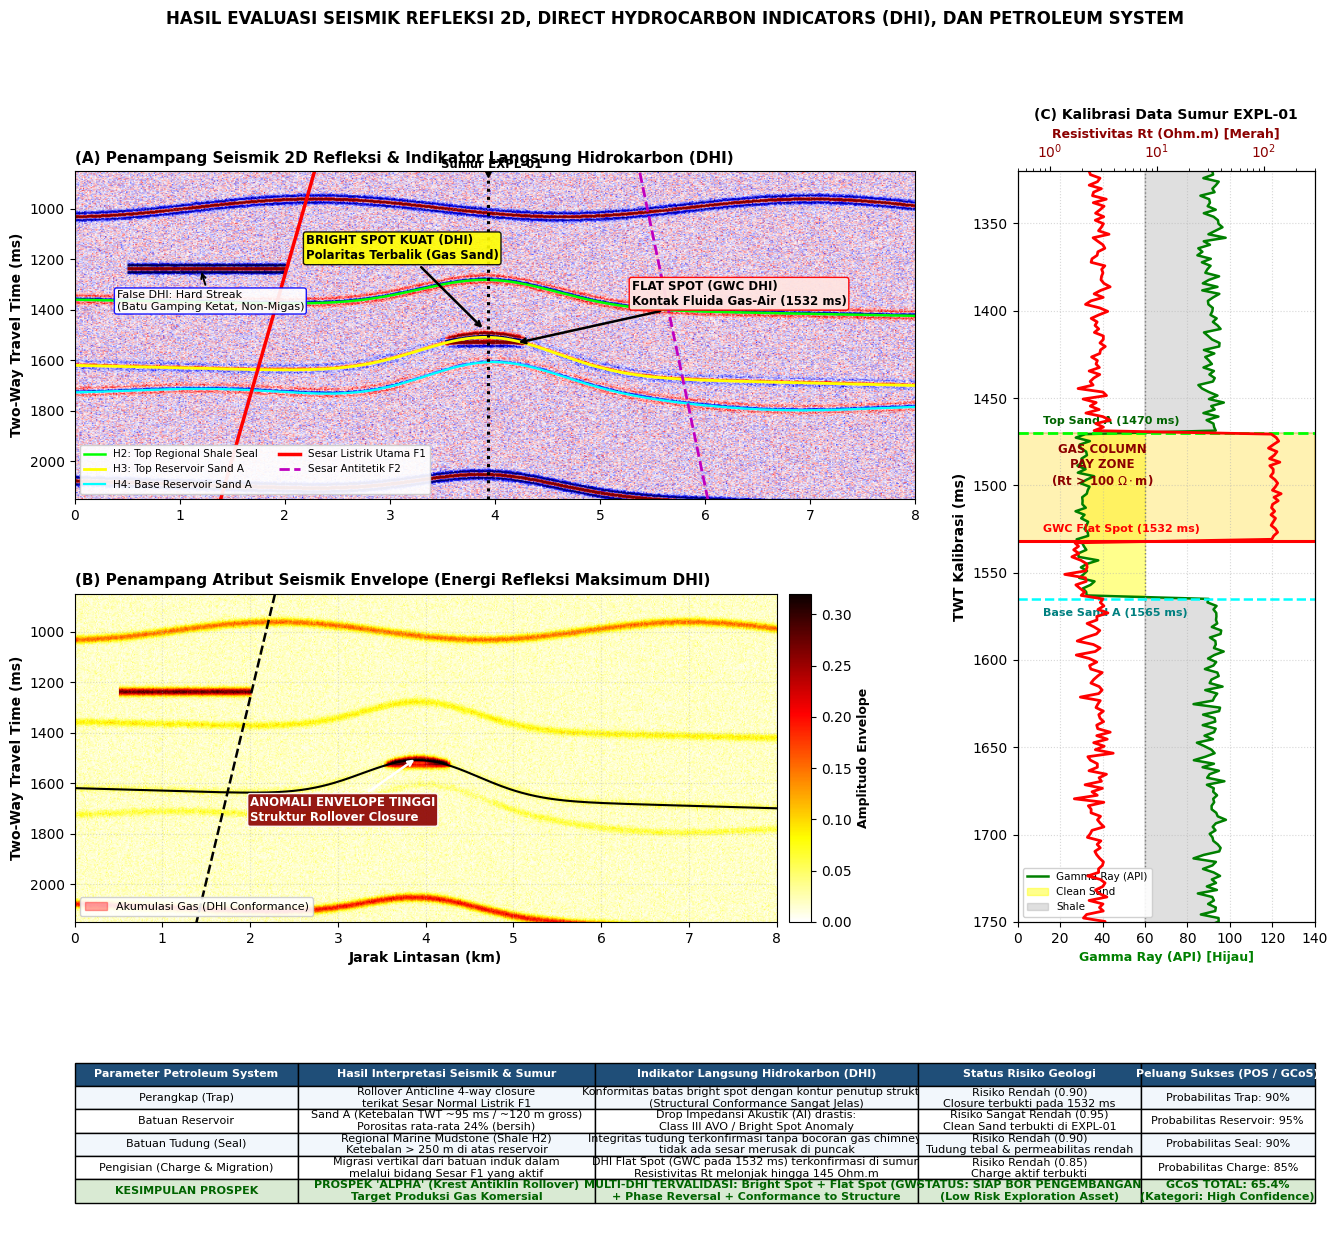

In [4]:
# %% [markdown]
# # EKSPLORASI MIGAS MENGGUNAKAN SEISMIK REFLEKSI & DIRECT HYDROCARBON INDICATORS (DHI)
# Interpretasi Seismik 2D, Atribut Envelope, Well-to-Seismic Tie, dan Petroleum System Modeling.
# Petunjuk VS Code: Klik tombol "Run Cell" (atau Shift + Enter) pada sel '# %%' di bawah.

# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from scipy.signal import hilbert

# 1. Parameter Grid Seismik 2D (TWT vs CMP)
cmp = np.arange(100, 741)
distance_km = (cmp - 100) * 0.0125  # 0 s.d 8 km (CMP spacing 12.5 m)
n_traces = len(cmp)

twt = np.arange(800, 2202, 2)       # Two-Way Travel Time: 800 - 2200 ms (dt = 2 ms)
n_samples = len(twt)
dt = 0.002

# 2. Stratigrafi, Antiklin Rollover & Sesar Listrik
fold_shape = np.exp(-((cmp - 415.0) / 75.0)**2)
tilt = (cmp - 100.0) * 0.25

h1_twt = 1000.0 + 35.0 * np.sin(cmp / 60.0)             # Dasar Laut / Unconformity
h2_twt = 1360.0 - 110.0 * fold_shape + tilt * 0.4       # Top Regional Shale Seal
h3_twt = 1620.0 - 150.0 * fold_shape + tilt * 0.5       # Top Reservoir Sand A
h4_twt = h3_twt + 95.0 + 15.0 * np.sin(cmp / 45.0)      # Base Reservoir Sand A
h5_twt = 2080.0 - 80.0 * fold_shape + tilt * 0.7       # Acoustic Basement

fault_f1_cmp = 280.0 - 0.055 * (twt - 900.0)            # Sesar Listrik Utama F1
fault_f1_dist = (fault_f1_cmp - 100.0) * 0.0125
fault_f2_cmp = 540.0 + 0.04 * (twt - 1100.0)            # Sesar Antitetik F2
fault_f2_dist = (fault_f2_cmp - 100.0) * 0.0125

gwc_twt = 1532.0  # Kontak Gas-Air (Flat Spot DHI)

# 3. Pemodelan Koefisien Refleksi & Konvolusi Wavelet Ricker
f_dom = 30.0
tw = np.arange(-0.06, 0.062, dt)
wavelet = (1.0 - 2.0 * (np.pi * f_dom * tw)**2) * np.exp(-(np.pi * f_dom * tw)**2)

RC = np.zeros((n_samples, n_traces))
for i, c_val in enumerate(cmp):
    RC[int(np.clip((h1_twt[i] - 800)/2, 0, n_samples - 1)), i] += 0.15
    RC[int(np.clip((h2_twt[i] - 800)/2, 0, n_samples - 1)), i] += -0.08
    
    # False DHI: Hard Streak Limestone (CMP 140 s.d 260 di TWT 1240 ms)
    if 140 <= c_val <= 260:
        RC[int(np.clip((1240.0 - 800)/2, 0, n_samples - 1)), i] += 0.28
    
    idx3 = int(np.clip((h3_twt[i] - 800)/2, 0, n_samples - 1))
    is_gas = (h3_twt[i] < gwc_twt) and (340 <= c_val <= 490)
    if is_gas:
        RC[idx3, i] += -0.28  # DHI: Bright Spot Kuat & Phase Reversal
        RC[int(np.clip((gwc_twt - 800)/2, 0, n_samples - 1)), i] += 0.22  # DHI: Flat Spot (GWC)
    else:
        RC[idx3, i] += 0.05   # Brine Sand: Refleksi Normal
        
    RC[int(np.clip((h4_twt[i] - 800)/2, 0, n_samples - 1)), i] += -0.06
    RC[int(np.clip((h5_twt[i] - 800)/2, 0, n_samples - 1)), i] += 0.20

seismic_data = np.zeros_like(RC)
for i in range(n_traces):
    conv_trace = np.convolve(RC[:, i], wavelet, mode='same')
    if 350 <= cmp[i] <= 480:
        idx_shadow = int((gwc_twt - 800)/2)
        conv_trace[idx_shadow:idx_shadow+120] *= 0.65 # DHI: Frequency Shadow
    seismic_data[:, i] = conv_trace

np.random.seed(42)
seismic_data += np.random.normal(0, 0.015, seismic_data.shape)
envelope = np.abs(hilbert(seismic_data, axis=0))

# 4. Data Log Sumur EXPL-01 (Krest Antiklin CMP 415)
well_x_km = (415 - 100) * 0.0125
well_twt = np.linspace(1300, 1800, 250)

gr_log = np.full_like(well_twt, 92.0)
sand_mask_well = (well_twt >= 1470) & (well_twt <= 1565)
gr_log[sand_mask_well] = 32.0 + np.random.normal(0, 2.5, np.sum(sand_mask_well))
gr_log[~sand_mask_well] += np.random.normal(0, 3.0, np.sum(~sand_mask_well))

rt_log = np.full_like(well_twt, 2.8)
gas_mask_well = (well_twt >= 1470) & (well_twt <= gwc_twt)
brine_sand_well = (well_twt > gwc_twt) & (well_twt <= 1565)
rt_log[gas_mask_well] = 125.0 + np.random.normal(0, 8.0, np.sum(gas_mask_well)) # Gas Pay (Rt tinggi)
rt_log[brine_sand_well] = 1.8 + np.random.normal(0, 0.3, np.sum(brine_sand_well))
rt_log[~sand_mask_well] += np.random.normal(0, 0.4, np.sum(~sand_mask_well))

# %% [markdown]
# ### Visualisasi Seismik & DHI di VS Code

# %%
fig = plt.figure(figsize=(16, 14), dpi=100)
gs = fig.add_gridspec(3, 2, width_ratios=[3.4, 1.2], height_ratios=[1.2, 1.2, 0.85], hspace=0.32, wspace=0.18)

# (A) Penampang Seismik Refleksi 2D
ax_seis = fig.add_subplot(gs[0, 0])
vm = np.percentile(np.abs(seismic_data), 98)
ax_seis.imshow(seismic_data, extent=[distance_km[0], distance_km[-1], twt[-1], twt[0]],
               aspect='auto', cmap='seismic', vmin=-vm, vmax=vm)

ax_seis.plot(distance_km, h2_twt, color='lime', lw=1.8, label='H2: Top Regional Shale Seal')
ax_seis.plot(distance_km, h3_twt, color='yellow', lw=2.0, label='H3: Top Reservoir Sand A')
ax_seis.plot(distance_km, h4_twt, color='cyan', lw=1.6, label='H4: Base Reservoir Sand A')

valid_f1 = (fault_f1_dist >= 0) & (fault_f1_dist <= 8.0)
ax_seis.plot(fault_f1_dist[valid_f1], twt[valid_f1], 'r-', lw=2.5, label='Sesar Listrik Utama F1')
valid_f2 = (fault_f2_dist >= 0) & (fault_f2_dist <= 8.0)
ax_seis.plot(fault_f2_dist[valid_f2], twt[valid_f2], 'm--', lw=2.0, label='Sesar Antitetik F2')

ax_seis.axvline(well_x_km, color='black', lw=2.2, linestyle=':')
ax_seis.plot(well_x_km, 850, 'kv', markersize=9)
ax_seis.text(well_x_km - 0.45, 840, 'Sumur EXPL-01', fontweight='bold', fontsize=8.5)

ax_seis.annotate('BRIGHT SPOT KUAT (DHI)\nPolaritas Terbalik (Gas Sand)', xy=(3.9, 1480), xytext=(2.2, 1200),
                 arrowprops=dict(facecolor='yellow', edgecolor='black', arrowstyle='->', lw=1.8),
                 fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='yellow', ec='black', alpha=0.9))

ax_seis.annotate('FLAT SPOT (GWC DHI)\nKontak Fluida Gas-Air (1532 ms)', xy=(4.2, 1532), xytext=(5.3, 1380),
                 arrowprops=dict(facecolor='red', edgecolor='black', arrowstyle='->', lw=1.8),
                 fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='mistyrose', ec='red', alpha=0.95))

ax_seis.annotate('False DHI: Hard Streak\n(Batu Gamping Ketat, Non-Migas)', xy=(1.2, 1240), xytext=(0.4, 1400),
                 arrowprops=dict(facecolor='blue', edgecolor='black', arrowstyle='->', lw=1.4),
                 fontsize=8.0, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='blue', alpha=0.9))

ax_seis.set_ylabel('Two-Way Travel Time (ms)', fontsize=10, fontweight='bold')
ax_seis.set_title('(A) Penampang Seismik 2D Refleksi & Indikator Langsung Hidrokarbon (DHI)', fontsize=11, fontweight='bold', loc='left')
ax_seis.set_xlim(0, 8.0); ax_seis.set_ylim(2150, 850)
ax_seis.grid(True, linestyle=':', alpha=0.4); ax_seis.legend(loc='lower left', fontsize=7.5, framealpha=0.92, ncol=2)

# (B) Atribut Seismik Envelope
ax_env = fig.add_subplot(gs[1, 0], sharex=ax_seis)
im2 = ax_env.imshow(envelope, extent=[distance_km[0], distance_km[-1], twt[-1], twt[0]],
                    aspect='auto', cmap='hot_r', vmin=0, vmax=0.32)
ax_env.plot(distance_km, h3_twt, 'k-', lw=1.5)
ax_env.plot(fault_f1_dist[valid_f1], twt[valid_f1], 'k--', lw=1.8)

gas_x = distance_km[(distance_km >= 2.9) & (distance_km <= 4.8)]
h3_gas = h3_twt[(distance_km >= 2.9) & (distance_km <= 4.8)]
ax_env.fill_between(gas_x, h3_gas, gwc_twt, where=(h3_gas <= gwc_twt), color='red', alpha=0.35, label='Akumulasi Gas (DHI Conformance)')

ax_env.annotate('ANOMALI ENVELOPE TINGGI\nStruktur Rollover Closure', xy=(3.9, 1500), xytext=(2.0, 1750),
                arrowprops=dict(facecolor='darkred', edgecolor='white', arrowstyle='->', lw=1.8),
                fontsize=8.5, color='white', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='darkred', ec='white', alpha=0.9))

ax_env.set_xlabel('Jarak Lintasan (km)', fontsize=10, fontweight='bold')
ax_env.set_ylabel('Two-Way Travel Time (ms)', fontsize=10, fontweight='bold')
ax_env.set_title('(B) Penampang Atribut Seismik Envelope (Energi Refleksi Maksimum DHI)', fontsize=11, fontweight='bold', loc='left')
ax_env.set_xlim(0, 8.0); ax_env.set_ylim(2150, 850)
ax_env.grid(True, linestyle=':', alpha=0.4); ax_env.legend(loc='lower left', fontsize=8, framealpha=0.9)
cbar_env = plt.colorbar(im2, ax=ax_env, pad=0.015, aspect=15)
cbar_env.set_label('Amplitudo Envelope', fontsize=9, fontweight='bold')

# (C) Log Sumur EXPL-01
ax_gr = fig.add_subplot(gs[0:2, 1])
ax_gr.plot(gr_log, well_twt, 'g-', lw=1.8, label='Gamma Ray (API)')
ax_gr.axvline(60, color='gray', linestyle=':', lw=1.0)
ax_gr.fill_betweenx(well_twt, gr_log, 60, where=(gr_log < 60), color='yellow', alpha=0.45, label='Clean Sand')
ax_gr.fill_betweenx(well_twt, gr_log, 60, where=(gr_log >= 60), color='gray', alpha=0.25, label='Shale')

ax_rt = ax_gr.twiny()
ax_rt.semilogx(rt_log, well_twt, 'r-', lw=2.0, label='Resistivitas Rt (Ohm.m)')
ax_rt.set_xlim(0.5, 300)
ax_rt.set_xlabel('Resistivitas Rt (Ohm.m) [Merah]', fontsize=9, color='darkred', fontweight='bold')
ax_rt.tick_params(axis='x', labelcolor='darkred')

ax_gr.axhline(1470, color='lime', lw=2.0, linestyle='--')
ax_gr.text(12, 1465, 'Top Sand A (1470 ms)', color='darkgreen', fontweight='bold', fontsize=8)
ax_gr.axhline(gwc_twt, color='red', lw=2.2, linestyle='-')
ax_gr.text(12, gwc_twt - 5, 'GWC Flat Spot (1532 ms)', color='red', fontweight='bold', fontsize=8)
ax_gr.axhline(1565, color='cyan', lw=1.8, linestyle='--')
ax_gr.text(12, 1575, 'Base Sand A (1565 ms)', color='teal', fontweight='bold', fontsize=8)

ax_gr.axhspan(1470, gwc_twt, facecolor='gold', alpha=0.3, edgecolor='darkgoldenrod', lw=1.5)
ax_gr.text(40, 1500, r'GAS COLUMN' + '\n' + r'PAY ZONE' + '\n' + r'(Rt > 100 $\Omega\cdot$m)', fontweight='bold', color='darkred', fontsize=8.5, ha='center')

ax_gr.set_ylabel('TWT Kalibrasi (ms)', fontsize=10, fontweight='bold')
ax_gr.set_xlabel('Gamma Ray (API) [Hijau]', fontsize=9, color='green', fontweight='bold')
ax_gr.set_xlim(0, 140); ax_gr.set_ylim(1750, 1320)
ax_gr.set_title('(C) Kalibrasi Data Sumur EXPL-01', fontsize=10, fontweight='bold')
ax_gr.grid(True, linestyle=':', alpha=0.5); ax_gr.legend(loc='lower left', fontsize=7.5, framealpha=0.9)

# (D) Tabel Evaluasi Prospek & Risiko Petroleum System
ax_tbl = fig.add_subplot(gs[2, :])
ax_tbl.axis('off')
table_data = [
    ["Parameter Petroleum System", "Hasil Interpretasi Seismik & Sumur", "Indikator Langsung Hidrokarbon (DHI)", "Status Risiko Geologi", "Peluang Sukses (POS / GCoS)"],
    ["Perangkap (Trap)", "Rollover Anticline 4-way closure\nterikat Sesar Normal Listrik F1", "Konformitas batas bright spot dengan kontur penutup struktur\n(Structural Conformance Sangat Jelas)", "Risiko Rendah (0.90)\nClosure terbukti pada 1532 ms", "Probabilitas Trap: 90%"],
    ["Batuan Reservoir", "Sand A (Ketebalan TWT ~95 ms / ~120 m gross)\nPorositas rata-rata 24% (bersih)", "Drop Impedansi Akustik (AI) drastis:\nClass III AVO / Bright Spot Anomaly", "Risiko Sangat Rendah (0.95)\nClean Sand terbukti di EXPL-01", "Probabilitas Reservoir: 95%"],
    ["Batuan Tudung (Seal)", "Regional Marine Mudstone (Shale H2)\nKetebalan > 250 m di atas reservoir", "Integritas tudung terkonfirmasi tanpa bocoran gas chimney,\ntidak ada sesar merusak di puncak", "Risiko Rendah (0.90)\nTudung tebal & permeabilitas rendah", "Probabilitas Seal: 90%"],
    ["Pengisian (Charge & Migration)", "Migrasi vertikal dari batuan induk dalam\nmelalui bidang Sesar F1 yang aktif", "DHI Flat Spot (GWC pada 1532 ms) terkonfirmasi di sumur;\nResistivitas Rt melonjak hingga 145 Ohm.m", "Risiko Rendah (0.85)\nCharge aktif terbukti", "Probabilitas Charge: 85%"],
    ["KESIMPULAN PROSPEK", "PROSPEK 'ALPHA' (Krest Antiklin Rollover)\nTarget Produksi Gas Komersial", "MULTI-DHI TERVALIDASI: Bright Spot + Flat Spot (GWC)\n+ Phase Reversal + Conformance to Structure", "STATUS: SIAP BOR PENGEMBANGAN\n(Low Risk Exploration Asset)", "GCoS TOTAL: 65.4%\n(Kategori: High Confidence)"]
]

tbl = ax_tbl.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.18, 0.24, 0.26, 0.18, 0.14])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.0); tbl.scale(1.0, 1.4)
for j in range(5):
    tbl[0, j].set_facecolor('#1f4e78'); tbl[0, j].set_text_props(color='white', fontweight='bold')
    tbl[5, j].set_facecolor('#d9ead3'); tbl[5, j].set_text_props(fontweight='bold', color='darkgreen')
for i in range(1, 5):
    bg_col = '#f2f7fc' if i % 2 == 1 else '#ffffff'
    for j in range(5):
        tbl[i, j].set_facecolor(bg_col)

plt.suptitle('HASIL EVALUASI SEISMIK REFLEKSI 2D, DIRECT HYDROCARBON INDICATORS (DHI), DAN PETROLEUM SYSTEM', fontsize=12, fontweight='bold', y=0.995)
plt.show() # Tampilkan langsung di jendela interaktif VS Code

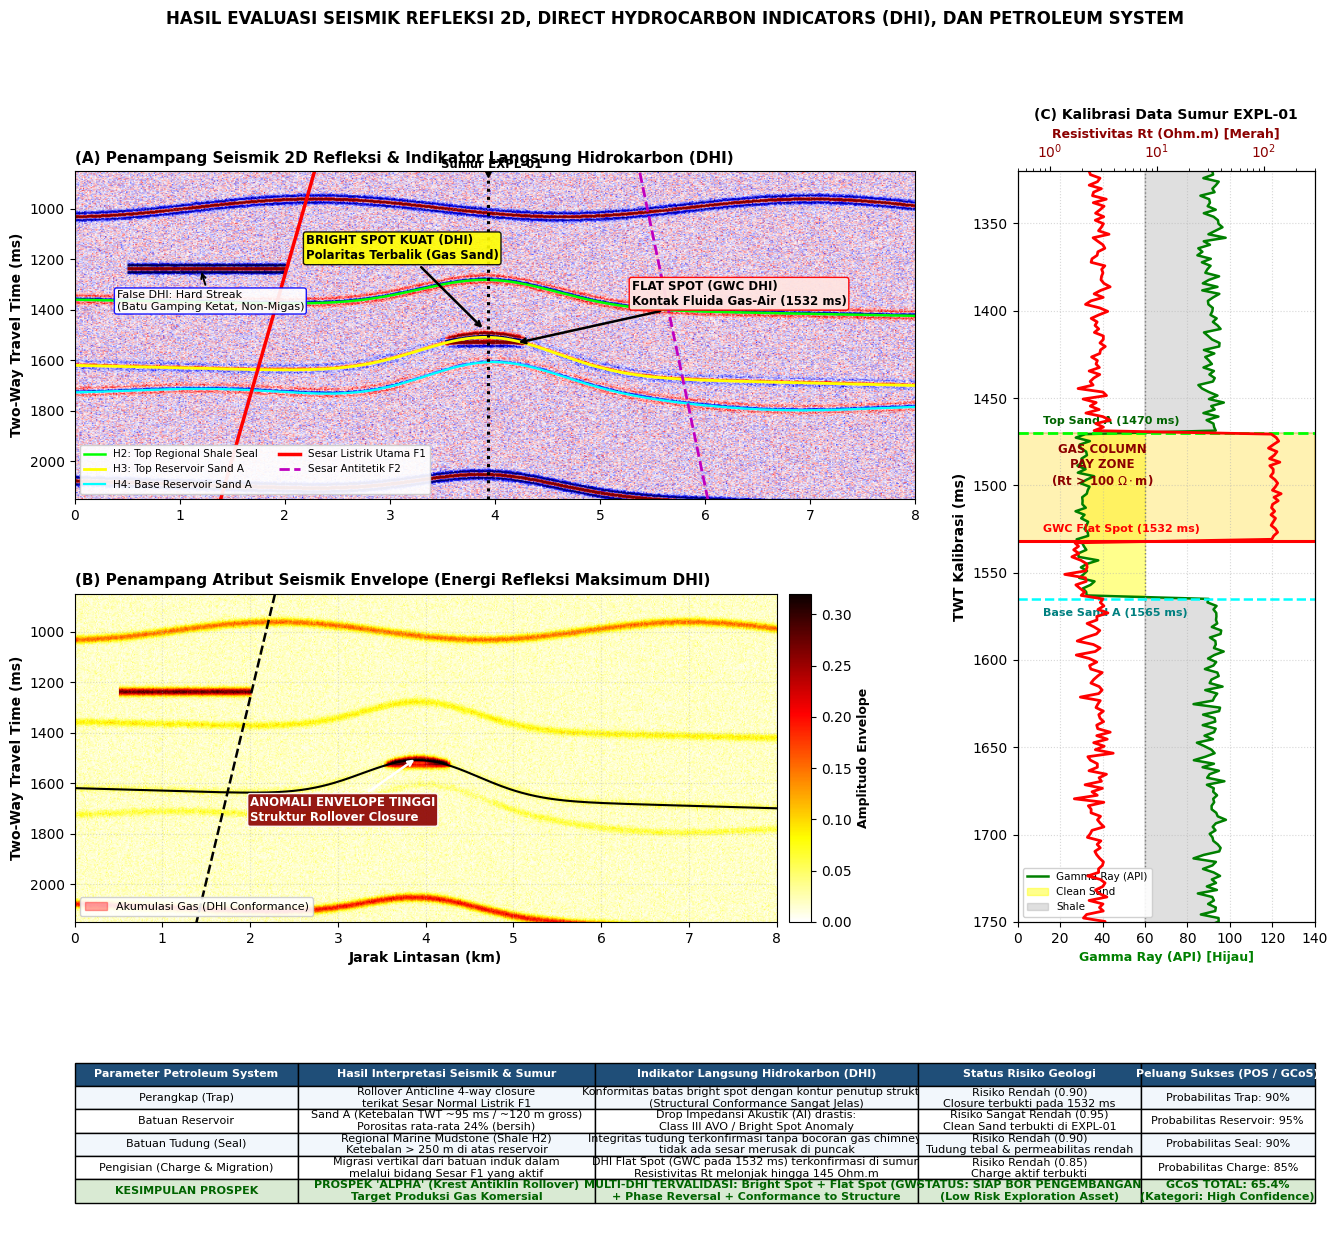

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from scipy.signal import hilbert

# 1. Parameter Grid Seismik 2D (TWT vs CMP)
cmp = np.arange(100, 741)
distance_km = (cmp - 100) * 0.0125  # 0 s.d 8 km (CMP spacing 12.5 m)
n_traces = len(cmp)

twt = np.arange(800, 2202, 2)       # Two-Way Travel Time: 800 - 2200 ms (dt = 2 ms)
n_samples = len(twt)
dt = 0.002

# 2. Stratigrafi, Antiklin Rollover & Sesar Listrik
fold_shape = np.exp(-((cmp - 415.0) / 75.0)**2)
tilt = (cmp - 100.0) * 0.25

h1_twt = 1000.0 + 35.0 * np.sin(cmp / 60.0)             # Dasar Laut / Unconformity
h2_twt = 1360.0 - 110.0 * fold_shape + tilt * 0.4       # Top Regional Shale Seal
h3_twt = 1620.0 - 150.0 * fold_shape + tilt * 0.5       # Top Reservoir Sand A
h4_twt = h3_twt + 95.0 + 15.0 * np.sin(cmp / 45.0)      # Base Reservoir Sand A
h5_twt = 2080.0 - 80.0 * fold_shape + tilt * 0.7       # Acoustic Basement

fault_f1_cmp = 280.0 - 0.055 * (twt - 900.0)            # Sesar Listrik Utama F1
fault_f1_dist = (fault_f1_cmp - 100.0) * 0.0125
fault_f2_cmp = 540.0 + 0.04 * (twt - 1100.0)            # Sesar Antitetik F2
fault_f2_dist = (fault_f2_cmp - 100.0) * 0.0125

gwc_twt = 1532.0  # Kontak Gas-Air (Flat Spot DHI)

# 3. Pemodelan Koefisien Refleksi & Konvolusi Wavelet Ricker
f_dom = 30.0
tw = np.arange(-0.06, 0.062, dt)
wavelet = (1.0 - 2.0 * (np.pi * f_dom * tw)**2) * np.exp(-(np.pi * f_dom * tw)**2)

RC = np.zeros((n_samples, n_traces))
for i, c_val in enumerate(cmp):
    RC[int(np.clip((h1_twt[i] - 800)/2, 0, n_samples - 1)), i] += 0.15
    RC[int(np.clip((h2_twt[i] - 800)/2, 0, n_samples - 1)), i] += -0.08
    
    # False DHI: Hard Streak Limestone (CMP 140 s.d 260 di TWT 1240 ms)
    if 140 <= c_val <= 260:
        RC[int(np.clip((1240.0 - 800)/2, 0, n_samples - 1)), i] += 0.28
    
    idx3 = int(np.clip((h3_twt[i] - 800)/2, 0, n_samples - 1))
    is_gas = (h3_twt[i] < gwc_twt) and (340 <= c_val <= 490)
    if is_gas:
        RC[idx3, i] += -0.28  # DHI: Bright Spot Kuat & Phase Reversal
        RC[int(np.clip((gwc_twt - 800)/2, 0, n_samples - 1)), i] += 0.22  # DHI: Flat Spot (GWC)
    else:
        RC[idx3, i] += 0.05   # Brine Sand: Refleksi Normal
        
    RC[int(np.clip((h4_twt[i] - 800)/2, 0, n_samples - 1)), i] += -0.06
    RC[int(np.clip((h5_twt[i] - 800)/2, 0, n_samples - 1)), i] += 0.20

seismic_data = np.zeros_like(RC)
for i in range(n_traces):
    conv_trace = np.convolve(RC[:, i], wavelet, mode='same')
    if 350 <= cmp[i] <= 480:
        idx_shadow = int((gwc_twt - 800)/2)
        conv_trace[idx_shadow:idx_shadow+120] *= 0.65 # DHI: Frequency Shadow
    seismic_data[:, i] = conv_trace

np.random.seed(42)
seismic_data += np.random.normal(0, 0.015, seismic_data.shape)
envelope = np.abs(hilbert(seismic_data, axis=0))

# 4. Data Log Sumur EXPL-01 (Krest Antiklin CMP 415)
well_x_km = (415 - 100) * 0.0125
well_twt = np.linspace(1300, 1800, 250)

gr_log = np.full_like(well_twt, 92.0)
sand_mask_well = (well_twt >= 1470) & (well_twt <= 1565)
gr_log[sand_mask_well] = 32.0 + np.random.normal(0, 2.5, np.sum(sand_mask_well))
gr_log[~sand_mask_well] += np.random.normal(0, 3.0, np.sum(~sand_mask_well))

rt_log = np.full_like(well_twt, 2.8)
gas_mask_well = (well_twt >= 1470) & (well_twt <= gwc_twt)
brine_sand_well = (well_twt > gwc_twt) & (well_twt <= 1565)
rt_log[gas_mask_well] = 125.0 + np.random.normal(0, 8.0, np.sum(gas_mask_well)) # Gas Pay (Rt tinggi)
rt_log[brine_sand_well] = 1.8 + np.random.normal(0, 0.3, np.sum(brine_sand_well))
rt_log[~sand_mask_well] += np.random.normal(0, 0.4, np.sum(~sand_mask_well))

# %% [markdown]
# ### Visualisasi Seismik & DHI di VS Code

# %%
fig = plt.figure(figsize=(16, 14), dpi=100)
gs = fig.add_gridspec(3, 2, width_ratios=[3.4, 1.2], height_ratios=[1.2, 1.2, 0.85], hspace=0.32, wspace=0.18)

# (A) Penampang Seismik Refleksi 2D
ax_seis = fig.add_subplot(gs[0, 0])
vm = np.percentile(np.abs(seismic_data), 98)
ax_seis.imshow(seismic_data, extent=[distance_km[0], distance_km[-1], twt[-1], twt[0]],
               aspect='auto', cmap='seismic', vmin=-vm, vmax=vm)

ax_seis.plot(distance_km, h2_twt, color='lime', lw=1.8, label='H2: Top Regional Shale Seal')
ax_seis.plot(distance_km, h3_twt, color='yellow', lw=2.0, label='H3: Top Reservoir Sand A')
ax_seis.plot(distance_km, h4_twt, color='cyan', lw=1.6, label='H4: Base Reservoir Sand A')

valid_f1 = (fault_f1_dist >= 0) & (fault_f1_dist <= 8.0)
ax_seis.plot(fault_f1_dist[valid_f1], twt[valid_f1], 'r-', lw=2.5, label='Sesar Listrik Utama F1')
valid_f2 = (fault_f2_dist >= 0) & (fault_f2_dist <= 8.0)
ax_seis.plot(fault_f2_dist[valid_f2], twt[valid_f2], 'm--', lw=2.0, label='Sesar Antitetik F2')

ax_seis.axvline(well_x_km, color='black', lw=2.2, linestyle=':')
ax_seis.plot(well_x_km, 850, 'kv', markersize=9)
ax_seis.text(well_x_km - 0.45, 840, 'Sumur EXPL-01', fontweight='bold', fontsize=8.5)

ax_seis.annotate('BRIGHT SPOT KUAT (DHI)\nPolaritas Terbalik (Gas Sand)', xy=(3.9, 1480), xytext=(2.2, 1200),
                 arrowprops=dict(facecolor='yellow', edgecolor='black', arrowstyle='->', lw=1.8),
                 fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='yellow', ec='black', alpha=0.9))

ax_seis.annotate('FLAT SPOT (GWC DHI)\nKontak Fluida Gas-Air (1532 ms)', xy=(4.2, 1532), xytext=(5.3, 1380),
                 arrowprops=dict(facecolor='red', edgecolor='black', arrowstyle='->', lw=1.8),
                 fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='mistyrose', ec='red', alpha=0.95))

ax_seis.annotate('False DHI: Hard Streak\n(Batu Gamping Ketat, Non-Migas)', xy=(1.2, 1240), xytext=(0.4, 1400),
                 arrowprops=dict(facecolor='blue', edgecolor='black', arrowstyle='->', lw=1.4),
                 fontsize=8.0, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='blue', alpha=0.9))

ax_seis.set_ylabel('Two-Way Travel Time (ms)', fontsize=10, fontweight='bold')
ax_seis.set_title('(A) Penampang Seismik 2D Refleksi & Indikator Langsung Hidrokarbon (DHI)', fontsize=11, fontweight='bold', loc='left')
ax_seis.set_xlim(0, 8.0); ax_seis.set_ylim(2150, 850)
ax_seis.grid(True, linestyle=':', alpha=0.4); ax_seis.legend(loc='lower left', fontsize=7.5, framealpha=0.92, ncol=2)

# (B) Atribut Seismik Envelope
ax_env = fig.add_subplot(gs[1, 0], sharex=ax_seis)
im2 = ax_env.imshow(envelope, extent=[distance_km[0], distance_km[-1], twt[-1], twt[0]],
                    aspect='auto', cmap='hot_r', vmin=0, vmax=0.32)
ax_env.plot(distance_km, h3_twt, 'k-', lw=1.5)
ax_env.plot(fault_f1_dist[valid_f1], twt[valid_f1], 'k--', lw=1.8)

gas_x = distance_km[(distance_km >= 2.9) & (distance_km <= 4.8)]
h3_gas = h3_twt[(distance_km >= 2.9) & (distance_km <= 4.8)]
ax_env.fill_between(gas_x, h3_gas, gwc_twt, where=(h3_gas <= gwc_twt), color='red', alpha=0.35, label='Akumulasi Gas (DHI Conformance)')

ax_env.annotate('ANOMALI ENVELOPE TINGGI\nStruktur Rollover Closure', xy=(3.9, 1500), xytext=(2.0, 1750),
                arrowprops=dict(facecolor='darkred', edgecolor='white', arrowstyle='->', lw=1.8),
                fontsize=8.5, color='white', fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='darkred', ec='white', alpha=0.9))

ax_env.set_xlabel('Jarak Lintasan (km)', fontsize=10, fontweight='bold')
ax_env.set_ylabel('Two-Way Travel Time (ms)', fontsize=10, fontweight='bold')
ax_env.set_title('(B) Penampang Atribut Seismik Envelope (Energi Refleksi Maksimum DHI)', fontsize=11, fontweight='bold', loc='left')
ax_env.set_xlim(0, 8.0); ax_env.set_ylim(2150, 850)
ax_env.grid(True, linestyle=':', alpha=0.4); ax_env.legend(loc='lower left', fontsize=8, framealpha=0.9)
cbar_env = plt.colorbar(im2, ax=ax_env, pad=0.015, aspect=15)
cbar_env.set_label('Amplitudo Envelope', fontsize=9, fontweight='bold')

# (C) Log Sumur EXPL-01
ax_gr = fig.add_subplot(gs[0:2, 1])
ax_gr.plot(gr_log, well_twt, 'g-', lw=1.8, label='Gamma Ray (API)')
ax_gr.axvline(60, color='gray', linestyle=':', lw=1.0)
ax_gr.fill_betweenx(well_twt, gr_log, 60, where=(gr_log < 60), color='yellow', alpha=0.45, label='Clean Sand')
ax_gr.fill_betweenx(well_twt, gr_log, 60, where=(gr_log >= 60), color='gray', alpha=0.25, label='Shale')

ax_rt = ax_gr.twiny()
ax_rt.semilogx(rt_log, well_twt, 'r-', lw=2.0, label='Resistivitas Rt (Ohm.m)')
ax_rt.set_xlim(0.5, 300)
ax_rt.set_xlabel('Resistivitas Rt (Ohm.m) [Merah]', fontsize=9, color='darkred', fontweight='bold')
ax_rt.tick_params(axis='x', labelcolor='darkred')

ax_gr.axhline(1470, color='lime', lw=2.0, linestyle='--')
ax_gr.text(12, 1465, 'Top Sand A (1470 ms)', color='darkgreen', fontweight='bold', fontsize=8)
ax_gr.axhline(gwc_twt, color='red', lw=2.2, linestyle='-')
ax_gr.text(12, gwc_twt - 5, 'GWC Flat Spot (1532 ms)', color='red', fontweight='bold', fontsize=8)
ax_gr.axhline(1565, color='cyan', lw=1.8, linestyle='--')
ax_gr.text(12, 1575, 'Base Sand A (1565 ms)', color='teal', fontweight='bold', fontsize=8)

ax_gr.axhspan(1470, gwc_twt, facecolor='gold', alpha=0.3, edgecolor='darkgoldenrod', lw=1.5)
ax_gr.text(40, 1500, r'GAS COLUMN' + '\n' + r'PAY ZONE' + '\n' + r'(Rt > 100 $\Omega\cdot$m)', fontweight='bold', color='darkred', fontsize=8.5, ha='center')

ax_gr.set_ylabel('TWT Kalibrasi (ms)', fontsize=10, fontweight='bold')
ax_gr.set_xlabel('Gamma Ray (API) [Hijau]', fontsize=9, color='green', fontweight='bold')
ax_gr.set_xlim(0, 140); ax_gr.set_ylim(1750, 1320)
ax_gr.set_title('(C) Kalibrasi Data Sumur EXPL-01', fontsize=10, fontweight='bold')
ax_gr.grid(True, linestyle=':', alpha=0.5); ax_gr.legend(loc='lower left', fontsize=7.5, framealpha=0.9)

# (D) Tabel Evaluasi Prospek & Risiko Petroleum System
ax_tbl = fig.add_subplot(gs[2, :])
ax_tbl.axis('off')
table_data = [
    ["Parameter Petroleum System", "Hasil Interpretasi Seismik & Sumur", "Indikator Langsung Hidrokarbon (DHI)", "Status Risiko Geologi", "Peluang Sukses (POS / GCoS)"],
    ["Perangkap (Trap)", "Rollover Anticline 4-way closure\nterikat Sesar Normal Listrik F1", "Konformitas batas bright spot dengan kontur penutup struktur\n(Structural Conformance Sangat Jelas)", "Risiko Rendah (0.90)\nClosure terbukti pada 1532 ms", "Probabilitas Trap: 90%"],
    ["Batuan Reservoir", "Sand A (Ketebalan TWT ~95 ms / ~120 m gross)\nPorositas rata-rata 24% (bersih)", "Drop Impedansi Akustik (AI) drastis:\nClass III AVO / Bright Spot Anomaly", "Risiko Sangat Rendah (0.95)\nClean Sand terbukti di EXPL-01", "Probabilitas Reservoir: 95%"],
    ["Batuan Tudung (Seal)", "Regional Marine Mudstone (Shale H2)\nKetebalan > 250 m di atas reservoir", "Integritas tudung terkonfirmasi tanpa bocoran gas chimney,\ntidak ada sesar merusak di puncak", "Risiko Rendah (0.90)\nTudung tebal & permeabilitas rendah", "Probabilitas Seal: 90%"],
    ["Pengisian (Charge & Migration)", "Migrasi vertikal dari batuan induk dalam\nmelalui bidang Sesar F1 yang aktif", "DHI Flat Spot (GWC pada 1532 ms) terkonfirmasi di sumur;\nResistivitas Rt melonjak hingga 145 Ohm.m", "Risiko Rendah (0.85)\nCharge aktif terbukti", "Probabilitas Charge: 85%"],
    ["KESIMPULAN PROSPEK", "PROSPEK 'ALPHA' (Krest Antiklin Rollover)\nTarget Produksi Gas Komersial", "MULTI-DHI TERVALIDASI: Bright Spot + Flat Spot (GWC)\n+ Phase Reversal + Conformance to Structure", "STATUS: SIAP BOR PENGEMBANGAN\n(Low Risk Exploration Asset)", "GCoS TOTAL: 65.4%\n(Kategori: High Confidence)"]
]

tbl = ax_tbl.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.18, 0.24, 0.26, 0.18, 0.14])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.0); tbl.scale(1.0, 1.4)
for j in range(5):
    tbl[0, j].set_facecolor('#1f4e78'); tbl[0, j].set_text_props(color='white', fontweight='bold')
    tbl[5, j].set_facecolor('#d9ead3'); tbl[5, j].set_text_props(fontweight='bold', color='darkgreen')
for i in range(1, 5):
    bg_col = '#f2f7fc' if i % 2 == 1 else '#ffffff'
    for j in range(5):
        tbl[i, j].set_facecolor(bg_col)

plt.suptitle('HASIL EVALUASI SEISMIK REFLEKSI 2D, DIRECT HYDROCARBON INDICATORS (DHI), DAN PETROLEUM SYSTEM', fontsize=12, fontweight='bold', y=0.995)
plt.show() # Tampilkan langsung di jendela interaktif VS Code

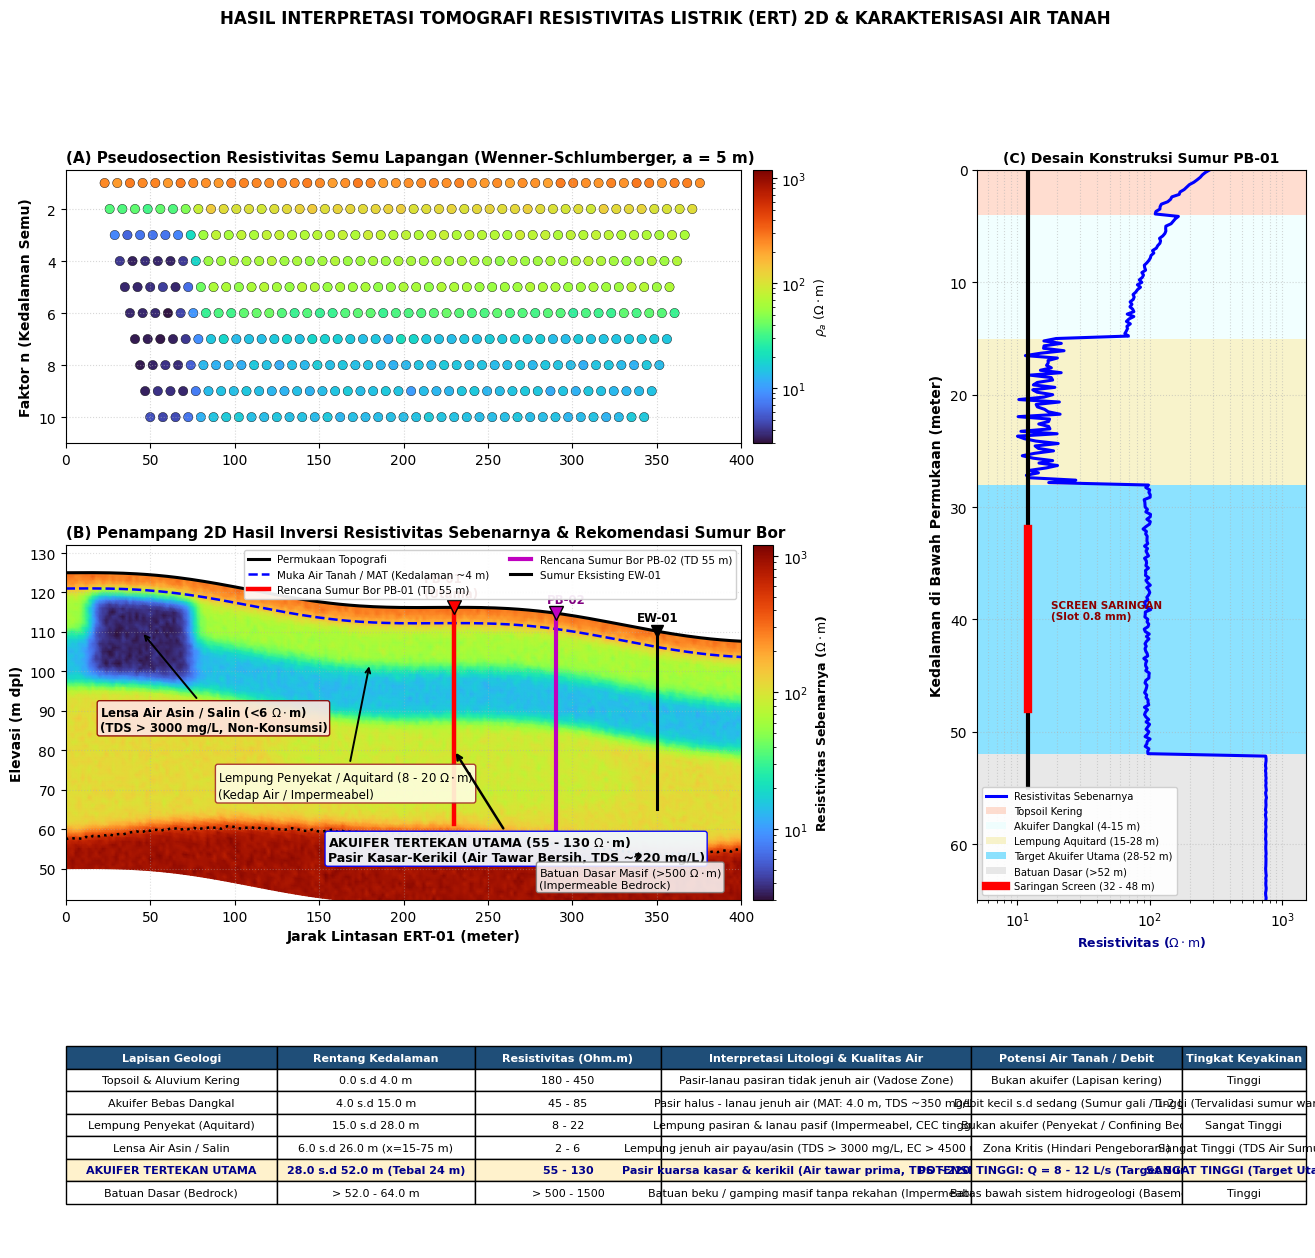

In [6]:
# %% [markdown]
# # PEMETAAN AIR TANAH MENGGUNAKAN ELECTRICAL RESISTIVITY TOMOGRAPHY (ERT)
# Pemodelan Inversi 2D ERT, Karakterisasi Akuifer Bebas vs Tertekan, Diskriminasi Lempung & Air Asin,
# Kalibrasi Data Sumur (TDS/EC), dan Rekomendasi Titik Pengeboran Sumur Produksi (PB-01 & PB-02).
# Petunjuk VS Code: Klik tombol "Run Cell" (atau Shift + Enter) pada sel '# %%' di bawah.

# %%
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from scipy.ndimage import gaussian_filter

# 1. Parameter Survei ERT, Grid 2D & Topografi
# Lintasan ERT-01: Panjang 400 m, 81 Elektroda, Spasi elektroda a = 5.0 m
dx, dz = 2.0, 1.0
x = np.arange(0, 402, dx)
z_rel = np.arange(0, 76, dz)  # Kedalaman 0 s.d 75 m
topo = 125.0 - 0.04 * x + 1.5 * np.sin(x / 35.0)

X, Z_rel = np.meshgrid(x, z_rel)
Z_elev = np.zeros_like(X)
for i in range(len(x)):
    Z_elev[:, i] = topo[i] - z_rel

# 2. Model Resistivitas Hidrogeologi Sebenarnya (True Model)
log_res_true = np.full_like(X, 2.05) # Batuan lapuk ~110 Ohm.m

# A. Lapisan Tanah Penutup Kering / Vadose Zone (0 - 4 m): 180 - 400 Ohm.m
log_res_true[Z_rel <= 4.0] = 2.45

# B. Akuifer Dangkal Bebas (Pasir Aluvial Halus, MAT ~4 m): 45 - 85 Ohm.m (TDS ~350 mg/L)
shallow_aq = (Z_rel > 4.0) & (Z_rel <= 15.0)
log_res_true[shallow_aq] = 1.80

# C. Lempung Penyekat / Aquitard (15 - 28 m): 8 - 20 Ohm.m (Impermeabel, konduksi lempung CEC)
aquitard_mask = (Z_rel > 15.0) & (Z_rel <= 28.0)
log_res_true[aquitard_mask] = 1.15

# D. Lensa Air Salin / Payau Dangkal di Barat (x = 15 - 75 m, 6 - 26 m): 2 - 6 Ohm.m (TDS > 3000 mg/L)
saline_mask = (X >= 15) & (X <= 75) & (Z_rel >= 6) & (Z_rel <= 26)
log_res_true[saline_mask] = 0.55

# E. AKUIFER TERTEKAN UTAMA (Pasir Kasar & Kerikil: 28 - 52 m, x = 120 - 340 m): 55 - 130 Ohm.m (Air Tawar)
dist_aq_x = (X - 230.0) / 105.0
dist_aq_z = (Z_rel - 40.0) / 12.0
log_res_true[(dist_aq_x**2 + dist_aq_z**2) <= 1.0] = 1.95

# F. Batuan Dasar Masif (>500 Ohm.m)
bedrock_depth = 64.0 - 0.03 * X + 2.5 * np.cos(X / 50.0)
log_res_true[Z_rel >= bedrock_depth] = 2.95

# 3. Simulasi Inversi 2D ERT
np.random.seed(42)
log_res_inv = gaussian_filter(log_res_true, sigma=(1.8, 2.2)) + np.random.normal(0, 0.035, log_res_true.shape)
res_inv = 10**log_res_inv

# 4. Simulasi Pseudosection Wenner-Schlumberger
n_pseudo = np.arange(1, 11)
x_pse, n_pse, res_pse = [], [], []
for n_val in n_pseudo:
    for x_mid in np.arange(20 + n_val*3, 380 - n_val*3, 7.5):
        depth_app = n_val * 5.0 * 0.519
        ix = int(np.clip(x_mid / dx, 0, len(x) - 1))
        iz = int(np.clip(depth_app / dz, 0, len(z_rel) - 1))
        x_pse.append(x_mid); n_pse.append(n_val); res_pse.append(res_inv[iz, ix] * (1.0 + np.random.normal(0, 0.04)))

x_pseudo, n_pseudo_arr, res_pseudo = np.array(x_pse), np.array(n_pse), np.array(res_pse)

# Titik Rencana Pemboran
pb1_x, pb1_el = 230.0, np.interp(230.0, x, topo)
pb2_x, pb2_el = 290.0, np.interp(290.0, x, topo)
ew1_x, ew1_el = 350.0, np.interp(350.0, x, topo)

# %% [markdown]
# ### Visualisasi ERT di VS Code

# %%
fig = plt.figure(figsize=(16, 14), dpi=100)
gs = fig.add_gridspec(3, 2, width_ratios=[3.2, 1.3], height_ratios=[1.0, 1.3, 0.9], hspace=0.35, wspace=0.18)

# (A) Pseudosection Resistivitas Semu
ax_pse = fig.add_subplot(gs[0, 0])
norm_ert = colors.LogNorm(vmin=3.0, vmax=1200.0)
sc_pse = ax_pse.scatter(x_pseudo, n_pseudo_arr, c=res_pseudo, cmap='turbo', norm=norm_ert, s=45, edgecolors='k', linewidths=0.3)
ax_pse.set_ylim(11.0, 0.5); ax_pse.set_xlim(0, 400)
ax_pse.set_ylabel('Faktor n (Kedalaman Semu)', fontsize=10, fontweight='bold')
ax_pse.set_title('(A) Pseudosection Resistivitas Semu Lapangan (Wenner-Schlumberger, a = 5 m)', fontsize=11, fontweight='bold', loc='left')
ax_pse.grid(True, linestyle=':', alpha=0.5)
cbar_pse = plt.colorbar(sc_pse, ax=ax_pse, pad=0.015, aspect=15)
cbar_pse.set_label(r'$\rho_a\ (\Omega\cdot\mathrm{m})$', fontsize=9, fontweight='bold')

# (B) Penampang 2D Hasil Inversi Resistivitas Sebenarnya
ax_inv = fig.add_subplot(gs[1, 0])
cs_inv = ax_inv.pcolormesh(X, Z_elev, res_inv, cmap='turbo', norm=norm_ert, shading='gouraud')
ax_inv.plot(x, topo, 'k-', lw=2.2, label='Permukaan Topografi')
ax_inv.plot(x, topo - 4.0, 'b--', lw=1.8, label='Muka Air Tanah / MAT (Kedalaman ~4 m)')
ax_inv.contour(X, Z_elev, res_inv, levels=[500], colors=['black'], linewidths=[1.8], linestyles=[':'])

# Rencana Titik Bor PB-01 & PB-02
ax_inv.plot([pb1_x, pb1_x], [pb1_el, pb1_el - 55], 'r-', lw=3.2, label='Rencana Sumur Bor PB-01 (TD 55 m)')
ax_inv.plot(pb1_x, pb1_el, 'rv', markersize=10, markeredgecolor='k')
ax_inv.text(pb1_x - 18, pb1_el + 2.5, 'PB-01\n(Utama)', fontweight='bold', color='darkred', fontsize=8.5)

ax_inv.plot([pb2_x, pb2_x], [pb2_el, pb2_el - 55], 'm-', lw=3.0, label='Rencana Sumur Bor PB-02 (TD 55 m)')
ax_inv.plot(pb2_x, pb2_el, 'mv', markersize=10, markeredgecolor='k')
ax_inv.text(pb2_x - 5, pb2_el + 2.5, 'PB-02', fontweight='bold', color='purple', fontsize=8.5)

ax_inv.plot([ew1_x, ew1_x], [ew1_el, ew1_el - 45], 'k-', lw=2.2, label='Sumur Eksisting EW-01')
ax_inv.plot(ew1_x, ew1_el, 'kv', markersize=8)
ax_inv.text(ew1_x - 12, ew1_el + 2.5, 'EW-01', fontweight='bold', fontsize=8.5)

# Anotasi Hidrogeologi
ax_inv.annotate(r'Lensa Air Asin / Salin (<6 $\Omega\cdot$m)' + '\n' + r'(TDS > 3000 mg/L, Non-Konsumsi)', 
                xy=(45, 110), xytext=(20, 85),
                arrowprops=dict(facecolor='darkred', arrowstyle='->', lw=1.4),
                fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='mistyrose', ec='darkred', alpha=0.9))

ax_inv.annotate(r'Lempung Penyekat / Aquitard (8 - 20 $\Omega\cdot$m)' + '\n' + r'(Kedap Air / Impermeabel)', 
                xy=(180, 102), xytext=(90, 68),
                arrowprops=dict(facecolor='brown', arrowstyle='->', lw=1.4),
                fontsize=8.5, bbox=dict(boxstyle='round,pad=0.2', fc='lightyellow', ec='brown', alpha=0.9))

ax_inv.annotate(r'AKUIFER TERTEKAN UTAMA (55 - 130 $\Omega\cdot$m)' + '\n' + r'Pasir Kasar-Kerikil (Air Tawar Bersih, TDS ~220 mg/L)', 
                xy=(230, 80), xytext=(155, 52),
                arrowprops=dict(facecolor='blue', arrowstyle='->', lw=1.8),
                fontsize=9.0, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='aliceblue', ec='blue', alpha=0.95))

ax_inv.annotate(r'Batuan Dasar Masif (>500 $\Omega\cdot$m)' + '\n' + r'(Impermeable Bedrock)', 
                xy=(340, 55), xytext=(280, 45),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=8.0, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.85))

ax_inv.set_xlabel('Jarak Lintasan ERT-01 (meter)', fontsize=10, fontweight='bold')
ax_inv.set_ylabel('Elevasi (m dpl)', fontsize=10, fontweight='bold')
ax_inv.set_xlim(0, 400); ax_inv.set_ylim(42, 132)
ax_inv.set_title('(B) Penampang 2D Hasil Inversi Resistivitas Sebenarnya & Rekomendasi Sumur Bor', fontsize=11, fontweight='bold', loc='left')
ax_inv.grid(True, linestyle=':', alpha=0.4); ax_inv.legend(loc='upper right', fontsize=7.5, framealpha=0.92, ncol=2)
cbar_inv = plt.colorbar(cs_inv, ax=ax_inv, pad=0.015, aspect=18)
cbar_inv.set_label(r'Resistivitas Sebenarnya ($\Omega\cdot\mathrm{m}$)', fontsize=9, fontweight='bold')

# (C) Desain Konstruksi Sumur PB-01
ax_log = fig.add_subplot(gs[0:2, 1])
depth_log = np.linspace(0, 65, 300)
res_log_pb1 = 280.0 * np.exp(-depth_log/4.0) + \
              60.0 * ((depth_log >= 4.0) & (depth_log < 15.0)) + \
              14.0 * ((depth_log >= 15.0) & (depth_log < 28.0)) + \
              95.0 * ((depth_log >= 28.0) & (depth_log < 52.0)) + \
              750.0 * (depth_log >= 52.0) + np.random.normal(0, 3.0, len(depth_log))

ax_log.semilogx(res_log_pb1, depth_log, 'b-', lw=2.2, label='Resistivitas Sebenarnya')
ax_log.set_xlim(5, 1500); ax_log.set_ylim(65, 0)
ax_log.set_xlabel(r'Resistivitas ($\Omega\cdot\mathrm{m}$)', fontsize=9, fontweight='bold', color='darkblue')
ax_log.set_ylabel('Kedalaman di Bawah Permukaan (meter)', fontsize=10, fontweight='bold')
ax_log.set_title('(C) Desain Konstruksi Sumur PB-01', fontsize=10, fontweight='bold')
ax_log.grid(True, which='both', linestyle=':', alpha=0.5)

ax_log.axhspan(0, 4, facecolor='lightsalmon', alpha=0.35, label='Topsoil Kering')
ax_log.axhspan(4, 15, facecolor='lightcyan', alpha=0.45, label='Akuifer Dangkal (4-15 m)')
ax_log.axhspan(15, 28, facecolor='khaki', alpha=0.45, label='Lempung Aquitard (15-28 m)')
ax_log.axhspan(28, 52, facecolor='deepskyblue', alpha=0.45, label='Target Akuifer Utama (28-52 m)')
ax_log.axhspan(52, 65, facecolor='lightgray', alpha=0.5, label='Batuan Dasar (>52 m)')

ax_log.plot([12, 12], [0, 55], 'k-', lw=3.0)
ax_log.plot([12, 12], [32, 48], 'r-', lw=6.0, label='Saringan Screen (32 - 48 m)')
ax_log.text(18, 40, 'SCREEN SARINGAN\n(Slot 0.8 mm)', color='darkred', fontweight='bold', fontsize=7.5)
ax_log.legend(loc='lower left', fontsize=7.2, framealpha=0.92)

# (D) Tabel Rekapitulasi Hidrogeologi
ax_tbl = fig.add_subplot(gs[2, :])
ax_tbl.axis('off')
table_data = [
    ["Lapisan Geologi", "Rentang Kedalaman", "Resistivitas (Ohm.m)", "Interpretasi Litologi & Kualitas Air", "Potensi Air Tanah / Debit", "Tingkat Keyakinan"],
    ["Topsoil & Aluvium Kering", "0.0 s.d 4.0 m", "180 - 450", "Pasir-lanau pasiran tidak jenuh air (Vadose Zone)", "Bukan akuifer (Lapisan kering)", "Tinggi"],
    ["Akuifer Bebas Dangkal", "4.0 s.d 15.0 m", "45 - 85", "Pasir halus - lanau jenuh air (MAT: 4.0 m, TDS ~350 mg/L)", "Debit kecil s.d sedang (Sumur gali / 1-2 L/s)", "Tinggi (Tervalidasi sumur warga)"],
    ["Lempung Penyekat (Aquitard)", "15.0 s.d 28.0 m", "8 - 22", "Lempung pasiran & lanau pasif (Impermeabel, CEC tinggi)", "Bukan akuifer (Penyekat / Conﬁning Bed)", "Sangat Tinggi"],
    ["Lensa Air Asin / Salin", "6.0 s.d 26.0 m (x=15-75 m)", "2 - 6", "Lempung jenuh air payau/asin (TDS > 3000 mg/L, EC > 4500 uS/cm)", "Zona Kritis (Hindari Pengeboran!)", "Sangat Tinggi (TDS Air Sumur)"],
    ["AKUIFER TERTEKAN UTAMA", "28.0 s.d 52.0 m (Tebal 24 m)", "55 - 130", "Pasir kuarsa kasar & kerikil (Air tawar prima, TDS ~220 mg/L)", "POTENSI TINGGI: Q = 8 - 12 L/s (Target Sumur Bor)", "SANGAT TINGGI (Target Utama)"],
    ["Batuan Dasar (Bedrock)", "> 52.0 - 64.0 m", "> 500 - 1500", "Batuan beku / gamping masif tanpa rekahan (Impermeabel)", "Batas bawah sistem hidrogeologi (Basement)", "Tinggi"]
]

tbl = ax_tbl.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.17, 0.16, 0.15, 0.25, 0.17, 0.10])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.0); tbl.scale(1.0, 1.35)
for j in range(6):
    tbl[0, j].set_facecolor('#1f4e78'); tbl[0, j].set_text_props(color='white', fontweight='bold')
    tbl[5, j].set_facecolor('#fff2cc'); tbl[5, j].set_text_props(fontweight='bold', color='darkblue')

plt.suptitle('HASIL INTERPRETASI TOMOGRAFI RESISTIVITAS LISTRIK (ERT) 2D & KARAKTERISASI AIR TANAH', fontsize=12, fontweight='bold', y=0.995)
plt.show() # Tampilkan langsung di jendela interaktif VS Code